# 3.4 Tetra-Fuse: a validation-selected five-member recipe

**Table 4** (held-out-test summary), **Figures S6/S7** (per-task raw-score box plots; leaderboard coverage vs rank), **Table 5** (per-task ensemble), **Table S8** (ensemble-vs-baseline significance), **Figure 5** (statistical validation forest plot). Recomputed from `../data/recompute_data/` via the shared setup cell.

In [1]:
# === Setup: figure/table regeneration for the ADMET multi-representation fusion paper ===
# Self-contained RECOMPUTATION from source predictions.
# Every figure/table quantity is recomputed here from raw per-seed per-molecule predictions
# (recompute_data/predictions/{model}.parquet), the per-model TDC leaderboard rankings
# (recompute_data/leaderboards/{model}.csv, direct training outputs), the 1023-subset uniform
# fusion sweep (recompute_data/all1023.csv), and the leaderboard
# ruler (recompute_data/tdc_leaderboard_snapshot.json). Nothing below is a hard-coded result;
# task metadata (ADMET group, training-set size, mechanism rationale) is loaded from
# recompute_data/task_metadata.json (fixed design labels, not recomputed). assert blocks verify the recomputed numbers against the
# manuscript values.
import os, json, io, itertools
from math import factorial
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import spearmanr, kendalltau, wilcoxon
from sklearn.metrics import roc_auc_score, average_precision_score, mean_absolute_error
from statsmodels.stats.multitest import multipletests

HERE = os.path.dirname(os.path.abspath("__file__")) if "__file__" in globals() else os.getcwd()
RELDATA = os.path.join(HERE, "..", "data")          # release data/ dir (single canonical copy)
DATA = os.path.join(RELDATA, "recompute_data")
OUTDIR = os.path.join(HERE, "..", "figures"); os.makedirs(OUTDIR, exist_ok=True)  # write figures into release figures/ dir
META_GREY = "#888888"

def apply_figure_style(*, frame="open", font=None, sizes=(8, 7, 6), grid=False):
    import matplotlib as mpl
    if frame not in ("open", "boxed", "none"):
        raise ValueError(f"frame must be 'open'|'boxed'|'none', got {frame!r}")
    try:
        import os, sys, glob, matplotlib.font_manager as fm
        fdir = os.path.join(os.environ.get("CONDA_PREFIX") or sys.prefix, "fonts")
        if os.path.isdir(fdir):
            known = {f.fname for f in fm.fontManager.ttflist}
            for f in glob.glob(os.path.join(fdir, "*.ttf")):
                if f not in known:
                    fm.fontManager.addfont(f)
    except Exception:
        pass
    base, secondary, tick = sizes
    boxed = (frame == "boxed")
    rc = {
        "font.family": "sans-serif", "font.size": base, "axes.labelsize": base,
        "axes.titlesize": base, "legend.fontsize": secondary, "xtick.labelsize": tick,
        "ytick.labelsize": tick, "axes.linewidth": 0.6,
        "xtick.direction": "out", "ytick.direction": "out",
        "xtick.major.size": 3, "ytick.major.size": 3,
        "xtick.major.width": 0.6, "ytick.major.width": 0.6,
        "axes.spines.top": boxed, "axes.spines.right": boxed,
        "axes.spines.left": frame != "none", "axes.spines.bottom": frame != "none",
        "axes.grid": bool(grid), "legend.frameon": False,
        "figure.dpi": 200, "savefig.dpi": 300, "savefig.bbox": "tight",
        "axes.titleweight": "normal", "axes.titlelocation": "left",
        "axes.labelweight": "normal", "lines.linewidth": 1.2, "patch.linewidth": 0.6,
        "pdf.fonttype": 42, "ps.fonttype": 42,
    }
    if font:
        rc["font.sans-serif"] = [font, "DejaVu Sans"]
    mpl.rcParams.update(rc)

REG  = json.load(open(f"{DATA}/task_registry.json"))
SNAP = json.load(open(f"{DATA}/tdc_leaderboard_snapshot.json"))
MODELS = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer","mtl_map",
          "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer","stl_map"]
TASKS  = [t for t in REG if t != "Bioavailability_Ma"]  # 21 evaluation tasks

def metric(name, y, p):
    """Compute a single TDC metric (mae/auroc/auprc/spearman) after dropping NaN labels."""
    y = np.asarray(y, float); p = np.asarray(p, float); m = ~np.isnan(y); y, p = y[m], p[m]
    if name == "mae":      return float(mean_absolute_error(y, p))
    if name == "auroc":    return float(roc_auc_score(y, p))
    if name == "auprc":    return float(average_precision_score(y, p))
    if name == "spearman": return float(spearmanr(y, p)[0])
    raise KeyError(name)

def norm_pct(score, task):
    """norm_score = fraction of TDC leaderboard models we beat (metric-direction aware)."""
    e = SNAP.get(task)
    if e is None or np.isnan(score): return np.nan
    s = [m["score"] for m in e["models"].values()]; met = REG[task]["metric"]
    worse = (sum(1 for x in s if x > score) if met == "mae" else sum(1 for x in s if x < score))
    return worse / len(s)

def rank_of(score, task):
    """Leaderboard rank of `score` for `task` (1 = best), metric-direction aware."""
    e = SNAP.get(task); met = REG[task]["metric"]
    s = [m["score"] for m in e["models"].values()]
    return (sum(1 for x in s if x < score) if met == "mae" else sum(1 for x in s if x > score)) + 1

# ---- load predictions (add replicate counter for exact merge keys) ----
PRED = {}
for m in MODELS:
    d = pd.read_parquet(f"{DATA}/predictions/{m}.parquet")
    PRED[m] = d.assign(rep=d.groupby(["seed","task","split","smiles"]).cumcount())

def merge_uniform(models, within):
    """Inner-join the given models' per-molecule predictions; add `yhat` = their uniform mean.
    within=True keeps the seed axis (matched-seed track); within=False averages predictions
    across seeds first (seed-averaged track). Returns the merged long DataFrame."""
    keys = ["seed","task","split","smiles","rep"] if within else ["task","split","smiles","rep"]
    if within:
        base = PRED[models[0]][keys+["y_true","y_pred"]].rename(columns={"y_pred":f"p_{models[0]}"})
        for m in models[1:]:
            base = base.merge(PRED[m][keys+["y_pred"]].rename(columns={"y_pred":f"p_{m}"}), on=keys, how="inner")
    else:
        sm = {m: PRED[m].groupby(["task","split","smiles","rep"])
                       .agg(y_true=("y_true","first"), y_pred=("y_pred","mean")).reset_index() for m in models}
        base = sm[models[0]][keys+["y_true","y_pred"]].rename(columns={"y_pred":f"p_{models[0]}"})
        for m in models[1:]:
            base = base.merge(sm[m][keys+["y_pred"]].rename(columns={"y_pred":f"p_{m}"}), on=keys, how="inner")
    base["yhat"] = base[[f"p_{m}" for m in models]].mean(axis=1)
    return base

def pertask_norm(models, within):
    """{task: norm_score} for the uniform-mean fusion of `models`, on the held-out test set.
    within=True: average the per-seed raw metric, then normalize once; within=False: score once on
    the seed-averaged predictions."""
    base = merge_uniform(models, within); res = {}
    for task in TASKS:
        met = REG[task]["metric"]
        t = base[(base.task==task)&(base.split=="test")].dropna(subset=["y_true"])
        if within:
            seed_sc = [metric(met, g.y_true, g.yhat) for _, g in t.groupby("seed")]
            res[task] = norm_pct(float(np.mean(seed_sc)), task)
        else:
            res[task] = norm_pct(metric(met, t.y_true, t.yhat), task)
    return res

def pertask_raw(models, within):
    """{task: raw_score} for the uniform-mean fusion of `models`, held-out test set.
    Mirror of pertask_norm but returns the raw metric value (before leaderboard normalization).
    within=True: mean over the per-seed metric (matched-seed track)."""
    base = merge_uniform(models, within); res = {}
    for task in TASKS:
        met = REG[task]["metric"]
        t = base[(base.task==task)&(base.split=="test")].dropna(subset=["y_true"])
        if within:
            res[task] = float(np.mean([metric(met, g.y_true, g.yhat) for _, g in t.groupby("seed")]))
        else:
            res[task] = float(metric(met, t.y_true, t.yhat))
    return res

def subset_norm(models, within):
    """Mean of pertask_norm across the 21 evaluation tasks (one scalar per subset)."""
    return float(np.mean(list(pertask_norm(models, within).values())))

# ---- correlation matrices (exact XAI method) ----
def corr_matrices(within):
    """Mean off-diagonal |correlation| among the k=5 ensemble members, for both the
    standardized predictions and the standardized residuals (prediction - truth).

    Returns (pred_corr, resid_corr): how redundant the members' outputs / errors are.
    within=True  -> matched-seed track: correlate per (task, seed), average the matrices.
    within=False -> seed-averaged track: pool all test rows per task, correlate once.
    (This is the exact 'XAI' correlation recipe used in the analysis notebooks.)
    """
    pred_cols = [f"p_{m}" for m in ENSEMBLE]
    base = merge_uniform(ENSEMBLE, within)
    if not within:
        # seed-averaged: concatenate standardized vectors across all tasks, one corr matrix
        pred_z  = {m: [] for m in ENSEMBLE}   # standardized predictions per member
        resid_z = {m: [] for m in ENSEMBLE}   # standardized residuals per member
        for task in TASKS:
            rows = base[(base.split=="test")&(base.task==task)].dropna(subset=["y_true"])
            y_true = rows.y_true.to_numpy(float); preds = rows[pred_cols].to_numpy(float)
            for j, m in enumerate(ENSEMBLE):
                p = preds[:, j]; pred_z[m].append((p - p.mean())/(p.std()+1e-9))
                resid = p - y_true; resid_z[m].append((resid - resid.mean())/(resid.std()+1e-9))
        pred_z  = {m: np.concatenate(v) for m, v in pred_z.items()}
        resid_z = {m: np.concatenate(v) for m, v in resid_z.items()}
        pred_corr_mat  = np.corrcoef([pred_z[m]  for m in ENSEMBLE])
        resid_corr_mat = np.corrcoef([resid_z[m] for m in ENSEMBLE])
    else:
        # matched-seed: one corr matrix per (task, seed), then average across all of them
        seeds = sorted(base.seed.unique()); pred_mats = []; resid_mats = []
        for task in TASKS:
            task_rows = base[base.task==task]
            for seed in seeds:
                seed_rows = task_rows[(task_rows.seed==seed)&(task_rows.split=="test")].dropna(subset=["y_true"])
                if len(seed_rows) < 3: continue
                y_true = seed_rows.y_true.to_numpy(float); preds = seed_rows[pred_cols].to_numpy(float)
                pred_z_seed = []; resid_z_seed = []
                for j, m in enumerate(ENSEMBLE):
                    p = preds[:, j]
                    pred_z_seed.append((p - p.mean())/(p.std()+1e-9))
                    resid_z_seed.append((p - y_true) - (p - y_true).mean()/((p - y_true).std()+1e-9))
                pred_mats.append(np.corrcoef(pred_z_seed)); resid_mats.append(np.corrcoef(resid_z_seed))
        pred_corr_mat  = np.nanmean(pred_mats, 0)
        resid_corr_mat = np.nanmean(resid_mats, 0)
    upper = np.triu_indices(len(ENSEMBLE), 1)   # off-diagonal (unordered pairs)
    return float(np.abs(pred_corr_mat[upper]).mean()), float(np.abs(resid_corr_mat[upper]).mean())

# ---- winners + best-single mean rank ----
def winners_best(within):
    """Per-task winner counts among the k=5 members + the best single member's mean TDC rank.

    Returns (wins, best_model, best_mean_rank):
      wins           - {model: number of tasks where it is the single best member}
      best_model     - member with the lowest mean leaderboard rank across tasks
      best_mean_rank - that member's mean rank (the single-model baseline the ensemble beats)
    within=True  -> matched-seed: winner decided per (task, seed); rank from seed-mean score.
    within=False -> seed-averaged: winner decided once per task on the seed-averaged score.
    """
    from collections import Counter
    base = merge_uniform(ENSEMBLE, within); pred_cols = [f"p_{m}" for m in ENSEMBLE]
    if not within:
        wins = Counter(); member_ranks = {m: [] for m in ENSEMBLE}   # per-task leaderboard rank
        for task in TASKS:
            met = REG[task]["metric"]
            rows = base[(base.split=="test")&(base.task==task)].dropna(subset=["y_true"])
            y_true = rows.y_true.to_numpy(float); preds = rows[pred_cols].to_numpy(float)
            member_score = {m: metric(met, y_true, preds[:, j]) for j, m in enumerate(ENSEMBLE)}
            wins[(min if met=="mae" else max)(member_score, key=member_score.get)] += 1
            for m in ENSEMBLE: member_ranks[m].append(rank_of(member_score[m], task))
    else:
        seeds = sorted(base.seed.unique()); wins = Counter(); member_score_by_task = {m: [] for m in ENSEMBLE}
        for task in TASKS:
            met = REG[task]["metric"]; task_rows = base[base.task==task]; seed_scores = {m: [] for m in ENSEMBLE}
            for seed in seeds:
                seed_rows = task_rows[(task_rows.seed==seed)&(task_rows.split=="test")].dropna(subset=["y_true"])
                if len(seed_rows)==0: continue
                y_true = seed_rows.y_true.to_numpy(float); preds = seed_rows[pred_cols].to_numpy(float)
                member_score = {m: metric(met, y_true, preds[:, j]) for j, m in enumerate(ENSEMBLE)}
                wins[(min if met=="mae" else max)(member_score, key=member_score.get)] += 1
                for m in ENSEMBLE: seed_scores[m].append(member_score[m])
            for m in ENSEMBLE: member_score_by_task[m].append(np.mean(seed_scores[m]))
        member_ranks = {m: [rank_of(member_score_by_task[m][i], TASKS[i]) for i in range(len(TASKS))] for m in ENSEMBLE}
    best_model = min(ENSEMBLE, key=lambda m: np.mean(member_ranks[m]))
    return dict(wins), best_model, float(np.mean(member_ranks[best_model]))

# ---- ensemble mean TDC rank (Score-then-Rank), within + cross ----
def ensemble_mean_rank():
    """Mean TDC leaderboard rank of the k=5 ensemble across tasks (Score-then-Rank).
    Returns (mean_rank_within, mean_rank_cross)."""
    bw = merge_uniform(ENSEMBLE, True); bc = merge_uniform(ENSEMBLE, False)
    ranks_w = []; ranks_c = []
    for task in TASKS:
        met = REG[task]["metric"]
        tw = bw[(bw.task==task)&(bw.split=="test")].dropna(subset=["y_true"])
        seed_sc = [metric(met, g.y_true, g.yhat) for _, g in tw.groupby("seed")]
        ranks_w.append(rank_of(float(np.mean(seed_sc)), task))
        tc = bc[(bc.task==task)&(bc.split=="test")].dropna(subset=["y_true"])
        ranks_c.append(rank_of(metric(met, tc.y_true, tc.yhat), task))
    return float(np.mean(ranks_w)), float(np.mean(ranks_c))

# ---- LOO + Shapley (over all 31 non-empty subsets of ENSEMBLE) ----
def loo_shapley():
    """Leave-one-out and Shapley contribution of each k=5 member to the ensemble norm_score.

    Enumerates all 31 non-empty subsets of ENSEMBLE and scores each (within + cross track):
      loo_within/cross    = value(full) - value(full minus this member)  (removal effect)
      shapley_within/cross= mean marginal contribution over all coalitions (Shapley value)
    Returns (per_member_dict, value_full_within, value_full_cross).
    """
    value_within = {}; value_cross = {}
    for size in range(1, len(ENSEMBLE)+1):
        for combo in itertools.combinations(ENSEMBLE, size):
            key = tuple(sorted(combo))
            value_within[key] = subset_norm(list(combo), True)
            value_cross[key]  = subset_norm(list(combo), False)
    full = tuple(sorted(ENSEMBLE)); n_members = len(ENSEMBLE)
    def shapley(value):
        contrib = {m: 0.0 for m in ENSEMBLE}
        for m in ENSEMBLE:
            others = [x for x in ENSEMBLE if x != m]
            for size in range(len(others)+1):
                for coalition in itertools.combinations(others, size):
                    weight = factorial(len(coalition))*factorial(n_members-len(coalition)-1)/factorial(n_members)
                    with_m    = value[tuple(sorted(coalition+(m,)))]
                    without_m = value[tuple(sorted(coalition))] if coalition else 0.0
                    contrib[m] += weight*(with_m - without_m)
        return contrib
    shap_within = shapley(value_within); shap_cross = shapley(value_cross); out = {}
    for m in ENSEMBLE:
        out[m] = {
            "within_solo": value_within[(m,)],
            "loo_within":  value_within[full] - value_within[tuple(sorted(x for x in ENSEMBLE if x!=m))],
            "cross_solo":  value_cross[(m,)],
            "loo_cross":   value_cross[full]  - value_cross[tuple(sorted(x for x in ENSEMBLE if x!=m))],
            "shapley_within": shap_within[m], "shapley_cross": shap_cross[m]}
    return out, value_within[full], value_cross[full]

# ---- MAP vs mean/max aggregation (leaderboard.csv `ours` -> re-ranked) ----
def map_agg():
    """MAP (joint latent fusion) vs naive mean/best aggregation of the 3 shared backbones,
    per training regime (mtl/stl). Uses leaderboard.csv `ours` scores re-normalized against
    the TDC snapshot. Returns (summary_dict, long_leaderboard_df)."""
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    LONG = pd.concat(lbs, ignore_index=True); LONG = LONG[LONG.dataset != "Bioavailability_Ma"]
    def to_norm(ds, score):
        e = SNAP.get(ds)
        if e is None or pd.isna(score): return np.nan
        met = REG[ds]["metric"]; s = [x["score"] for x in e["models"].values()]
        rank = (sum(1 for x in s if x < score) if met=="mae" else sum(1 for x in s if x > score))+1
        return (len(s)-rank+1)/len(s)
    BACKS = ["chemeleon","graphmvp","molformer"]; res = {}
    for train in ["mtl","stl"]:
        bm = [f"{train}_{b}" for b in BACKS]
        piv = LONG[LONG.model.isin(bm)].pivot_table(index=["dataset","metric"], columns="model", values="ours", aggfunc="first")
        mp = LONG[LONG.model==f"{train}_map"].set_index("dataset").apply(lambda r: to_norm(r.name, r["ours"]), axis=1)
        mn = {}; mx = {}
        for (ds,met),row in piv.iterrows():
            vals = row[bm].dropna()
            if vals.empty: continue
            direction = SNAP.get(ds,{}).get("direction","higher")
            mn[ds] = to_norm(ds, vals.mean()); mx[ds] = to_norm(ds, vals.max() if direction=="higher" else vals.min())
        common = [d for d in mp.index if d in mn]
        mpv = mp[common]; mnv = pd.Series(mn)[common]; mxv = pd.Series(mx)[common]
        res[train] = {"map":round(float(mpv.mean()),3),"mean":round(float(mnv.mean()),3),"best":round(float(mxv.mean()),3),
                      "map_gt_mean":f"{int((mpv>mnv).sum())}/{len(common)}",
                      "map_gt_best":f"{int((mpv>mxv).sum())}/{len(common)}","n":len(common)}
    return res, LONG

# ---- ensemble-size sweep (top-20 mean per k over 1023 uniform subsets) ----
def ksweep():
    # all1023.csv: the uniform-mean fusion sweep over all 1,023 non-empty subsets of the 10
    #   base models, scored on both validation and the held-out TDC test split (matched-seed
    #   'within' and seed-averaged 'cross' tracks). One row per subset; columns:
    #   combo_key (comma-joined member list), k, {val,test}_{within,cross}, {val,test}_comb.
    #   The ensemble-size selection uses the VALIDATION columns only (val_within/val_cross);
    #   the test columns are the same file's source for the Figure 6 reliability scatter.
    #   Feeds Figure 4 + Table S3 (validation top-20-mean norm_score per k -> elbow at k=5).
    #   This file is fully regenerable from the 10 predictions/*.parquet via code/make_all1023.py
    #   (predictions -> script -> csv closure); nothing here is hard-coded.
    s1 = pd.read_csv(f"{DATA}/all1023.csv")
    s1["k"] = s1.combo_key.apply(lambda b: len(b.split(",")))
    def topN(col, N=20):
        return {k: round(s1[s1.k==k].nlargest(min(N,(s1.k==k).sum()), col)[col].mean(),4) for k in range(1,11)}
    tw = topN("val_within"); tc = topN("val_cross")
    rows = []
    for k in range(1,11):
        rows.append([k, tw[k], round(tw[k]-tw[k-1],4) if k>1 else None,
                        tc[k], round(tc[k]-tc[k-1],4) if k>1 else None])
    return rows

# ---- validation->test rank reliability (all 1023 subsets) ----
def val_test_corr():
    # all1023.csv: uniform-mean fusion scored on BOTH validation and the fixed TDC test set,
    #   for every one of the 1,023 non-empty subsets. One row per subset; columns:
    #   combo_key (member list), k, val_within, val_cross, test_within, test_cross,
    #   val_comb, test_comb. This is the source for Figure 6A's validation->test rank
    #   reliability scatter, which uses the val_* -> test_* columns of the same sweep file.
    #   Same source as ksweep() (Figure 4); regenerable via code/make_all1023.py.
    from scipy.stats import spearmanr as _sp, kendalltau as _kt
    a = pd.read_csv(f"{DATA}/all1023.csv"); out = {}
    for name,vc,tc in [("within","val_within","test_within"),("cross","val_cross","test_cross"),("combined","val_comb","test_comb")]:
        out[name] = {"rho": round(_sp(a[vc],a[tc])[0],4), "tau": round(_kt(a[vc],a[tc])[0],4)}
    out["n_configs"] = len(a); return out

# ---- statistical tests (ensemble vs deployable singles + per-task oracle) ----
def stat_tests():
    ens_w = pertask_norm(ENSEMBLE, True); ens_c = pertask_norm(ENSEMBLE, False)
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    LONG = pd.concat(lbs, ignore_index=True); LONG = LONG[LONG.dataset != "Bioavailability_Ma"]
    LONG["norm"] = (LONG.n_total - LONG["rank"] + 1)/LONG.n_total
    lbp = LONG.pivot_table(index="dataset", columns="model", values="norm").loc[TASKS]
    baselines = {"CheMeleon\u00b7STL":"stl_chemeleon","MAP\u00b7STL":"stl_map","D-MPNN\u00b7MTL":"mtl_dmpnn"}
    dep = {}; ora = {}
    for track, ens in [("within", ens_w), ("cross", ens_c)]:
        e = np.array([ens[t] for t in TASKS])
        for disp, m in baselines.items():
            b = lbp[m].to_numpy(); de = e - b; w = wilcoxon(de, alternative="greater", zero_method="wilcox")
            dep[f"{disp}|{track}"] = {"median":float(np.median(de)),"mean":float(de.mean()),"W":float(w.statistic),
                "p":float(w.pvalue),"wtl":f"{int((de>0).sum())}/{int((de==0).sum())}/{int((de<0).sum())}","base_mean":float(b.mean())}
        oc = lbp.max(axis=1).to_numpy(); de = e - oc; w = wilcoxon(de, alternative="greater", zero_method="wilcox")
        ora[track] = {"median":float(np.median(de)),"mean":float(de.mean()),"W":float(w.statistic),
            "p":float(w.pvalue),"wtl":f"{int((de>0).sum())}/{int((de==0).sum())}/{int((de<0).sum())}","base_mean":float(oc.mean())}
    return {"deployable_single":dep, "per_task_oracle":ora, "n_tasks":len(TASKS),
            "ensemble_mean":{"within":float(np.mean(list(ens_w.values()))),"cross":float(np.mean(list(ens_c.values())))}}

# ---- per-task tables t1 (per-backbone), t3 (MAP/mean/max), t4 (ensemble) ----
def leaderboard_long():
    """Concatenate every model's leaderboard.csv into one long frame with a `norm` column."""
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    L = pd.concat(lbs, ignore_index=True)
    L["norm"] = (L.n_total - L["rank"] + 1)/L.n_total
    return L

def table_t1(meta):
    """per-backbone per-task raw+norm on the WITHIN-SEED (matched-seed) basis: each seed is
    scored separately, the five raw scores are averaged, and that mean is normalized once (identical
    basis to Figure 1a / Table 4). meta = {task:{group,n}}. norm rounded to 3 decimals."""
    BB = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer",
          "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer"]
    raw = {b: pertask_raw([b], True)  for b in BB}
    nrm = {b: pertask_norm([b], True) for b in BB}
    rows = []
    for task, mrec in meta.items():
        e = {"group": mrec["group"], "dataset": task, "n": mrec["n"], "metric": REG[task]["metric"]}
        for b in BB:
            e[b] = {"raw": round(float(raw[b][task]),3), "norm": round(float(nrm[b][task]),3)}
        rows.append(e)
    return rows

def table_t3(meta3):
    """MAP / latent-mean / latent-best per-task raw+norm on the WITHIN-SEED basis. MAP is the
    joint-fusion model's own per-seed prediction; latent mean/best aggregate the three backbones'
    per-seed scores (mean or direction-aware best) per seed, then norm and average. meta3 = {task:{group}}."""
    BACKS = ["chemeleon","graphmvp","molformer"]
    def agg_within(train, task, how):
        # Reference lines for the three MAP backbones, on the SAME basis as every other
        # normalized value in this release (Method A): aggregate in RAW score space first,
        # normalize exactly once at the end.
        #   step 1  per encoder, average the raw metric over the five seeds (= its Table S1 value)
        #   step 2  across the three encoders take the mean, or the best in the metric direction
        #   step 3  map that single raw value through norm_pct once
        # Aggregating inside each seed and normalizing per seed instead would make `best` a
        # per-seed oracle whose raw value matches no individual backbone, and would break
        # monotonicity between the raw and normalized columns because norm_pct is a step
        # function of the raw metric.
        met = REG[task]["metric"]
        enc_raw = {}
        for bb in BACKS:
            d = PRED[f"{train}_{bb}"]
            per_seed = []
            for seed in sorted(d.seed.unique()):
                t = d[(d.task==task)&(d.split=="test")&(d.seed==seed)].dropna(subset=["y_true"])
                per_seed.append(metric(met, t.y_true, t.y_pred))
            enc_raw[bb] = float(np.mean(per_seed))
        vals = list(enc_raw.values())
        raw = float(np.mean(vals)) if how=="mean" else float(min(vals) if met=="mae" else max(vals))
        return raw, float(norm_pct(raw, task))
    map_raw = {tr: pertask_raw([f"{tr}_map"], True)  for tr in ["mtl","stl"]}
    map_nrm = {tr: pertask_norm([f"{tr}_map"], True) for tr in ["mtl","stl"]}
    rows = []
    for task, mrec in meta3.items():
        met = REG[task]["metric"]; e = {"group": mrec["group"], "dataset": task, "metric": met}
        for train in ["mtl","stl"]:
            e[f"{train}_map"]  = {"raw": round(float(map_raw[train][task]),3), "norm": round(float(map_nrm[train][task]),3)}
            mr, mn = agg_within(train, task, "mean"); br, bn = agg_within(train, task, "best")
            e[f"{train}_mean"] = {"raw": round(mr,3), "norm": round(mn,3)}
            e[f"{train}_best"] = {"raw": round(br,3), "norm": round(bn,3)}
        rows.append(e)
    return rows

def table_t4():
    """ensemble per-task within/cross score+norm+rank over ALL 22 tasks (incl Bioavailability_Ma)."""
    allt = list(REG)
    bw = merge_uniform(ENSEMBLE, True); bc = merge_uniform(ENSEMBLE, False); rows = []
    for task in allt:
        met = REG[task]["metric"]
        tw = bw[(bw.task==task)&(bw.split=="test")].dropna(subset=["y_true"])
        seed_sc = [metric(met, g.y_true, g.yhat) for _, g in tw.groupby("seed")]
        ws = float(np.mean(seed_sc)); ws_std = float(np.std(seed_sc, ddof=0))  # ddof=0 matches TDC ours_std
        tc = bc[(bc.task==task)&(bc.split=="test")].dropna(subset=["y_true"])
        cs = metric(met, tc.y_true, tc.yhat)
        def _n(x, nd=3):  # int for exact 0/1 (match hardcoded schema), else float rounded to nd
            return int(x) if float(x).is_integer() else round(float(x), nd)
        rows.append({"task":task, "metric":met,
                     "within_score":round(ws,6), "within_std":round(ws_std,6), "within_norm":_n(norm_pct(ws,task),3), "within_rank":rank_of(ws,task),
                     "cross_score":round(cs,6),  "cross_norm":_n(norm_pct(cs,task),3),  "cross_rank":rank_of(cs,task)})
    return rows

# ---- Figure-1 within-seed solo + per-task (predictions basis) ----
def fig1_data(groups):
    """Figure 1 inputs on the within-seed (matched-seed) basis: per-model solo norm_score
    (`solo`), per-model per-task norm (`pertask`), and the ADMET mechanism `groups`."""
    solo = {m: subset_norm([m], True) for m in MODELS}
    pertask = []
    for task in TASKS:
        rec = {"task": task}
        for m in MODELS:
            rec[m] = pertask_norm([m], True)[task]
        pertask.append(rec)
    return {"solo": solo, "pertask": pertask, "groups": groups}

# ---- assemble full _GT / _PT / _FIG1 / _ST ----
def build_all(meta1, meta3, groups, t2, const_gt):
    lo, ens_w, ens_c = loo_shapley()
    cw = corr_matrices(True); cc = corr_matrices(False)
    win_w, bs_w, bsr_w = winners_best(True); win_c, bs_c, bsr_c = winners_best(False)
    mag, _ = map_agg()
    GT = dict(const_gt)  # final_ensemble, headline, sota_tasks, etc (constants)
    GT["map_agg"] = {t: {k: mag[t][k] for k in ["map","mean","best","map_gt_mean","map_gt_best"]} for t in ["mtl","stl"]}
    GT["ksweep"] = ksweep()
    GT["corr"] = {"within": {"pred_offdiag": round(cw[0],3), "resid_offdiag": round(cw[1],3)},
                  "cross":  {"pred_offdiag": round(cc[0],3), "resid_offdiag": round(cc[1],3)}}
    # ens_rank = mean TDC rank of the k=5 uniform ensemble across the 21 tasks (Score-then-Rank),
    # recomputed here (NOT a literal): within uses per-seed→mean→rank, cross uses seed-meaned→rank.
    ens_rank_w, ens_rank_c = ensemble_mean_rank()
    GT["best_single"] = {"within": {"model": bs_w, "mean_rank": round(bsr_w,3), "ens_rank": round(ens_rank_w,3)},
                         "cross":  {"model": bs_c, "mean_rank": round(bsr_c,3), "ens_rank": round(ens_rank_c,3)}}
    # per member -> [0]=within_solo  [1]=loo_within  [2]=cross_solo
    #                [3]=loo_cross    [4]=shapley_within  [5]=shapley_cross
    GT["loo_shapley"] = {b: [round(lo[b]["within_solo"],4), round(lo[b]["loo_within"],4),
                             round(lo[b]["cross_solo"],4), round(lo[b]["loo_cross"],4),
                             round(lo[b]["shapley_within"],4), round(lo[b]["shapley_cross"],4)] for b in ENSEMBLE}
    GT["winners"] = {"cross": {m: win_c.get(m,0) for m in ENSEMBLE},
                     "within_taskseed": {m: win_w.get(m,0) for m in ENSEMBLE}}
    GT["full_ensemble_norm"] = {"within": round(ens_w,4), "cross": round(ens_c,4)}
    PT = {"t1": table_t1(meta1), "t3": table_t3(meta3), "t4": table_t4(), "t2": t2}
    FIG1 = fig1_data(groups)
    ST = stat_tests()
    return GT, PT, FIG1, ST


# --- task metadata (fixed design labels, not recomputed): loaded from recompute_data/task_metadata.json ---
_TASK_META = json.load(open(f"{DATA}/task_metadata.json"))
_META1   = _TASK_META["meta1"]                                   # {task: {group, n}}
_META3   = {t: {"group": v["group"]} for t, v in _META1.items()} # meta1 without training-set size
_GROUPS  = _TASK_META["groups"]                                  # {mechanism group: [tasks]}
_T2      = _TASK_META["t2"]                                      # [{group, tasks, rationale}]
_CONST_GT = _TASK_META["const_gt"]                               # final_ensemble / final_composition / ...
ENSEMBLE  = list(_CONST_GT["final_ensemble"])                    # final k=5 members (single source of truth)


# --- recompute everything from source ---
_GT, _PT, _FIG1, _ST = build_all(_META1, _META3, _GROUPS, _T2, _CONST_GT)

# --- solo per-task within/cross norm (recomputed from predictions+leaderboards; replaces solo_pertask_within_cross.csv / fig1_within_pertask.csv) ---
# Per-(model, task) solo within/cross norm_score, recomputed from source predictions +
# leaderboard rankings. Replaces the released solo_pertask_within_cross.csv and
# fig1_within_pertask.csv (values verified identical to 1e-16).
# Row order matters ONLY for Figure 6B's winner-per-task argmax under exact norm ties
# (several tasks tie to the 4th decimal); we emit rows in the exact model/task order of
# the original fig1_within_pertask.csv so idxmax tie-breaking reproduces the published
# Figure 6B winner distribution (8/5/4/3/1). The norm values themselves are order-independent.
_SOLO_MODEL_ORDER = ["mtl_dmpnn","stl_dmpnn","stl_map","stl_chemeleon","stl_graphmvp",
                     "stl_molformer","mtl_graphmvp","mtl_molformer","mtl_chemeleon","mtl_map"]
_SOLO_TASK_ORDER  = ["HIA_Hou","Pgp_Broccatelli","BBB_Martins","CYP2C9_Veith","CYP2D6_Veith",
                     "CYP3A4_Veith","CYP2C9_Substrate_CarbonMangels","CYP2D6_Substrate_CarbonMangels",
                     "CYP3A4_Substrate_CarbonMangels","hERG","AMES","DILI","Caco2_Wang",
                     "Lipophilicity_AstraZeneca","Solubility_AqSolDB","PPBR_AZ","VDss_Lombardo",
                     "Half_Life_Obach","Clearance_Hepatocyte_AZ","Clearance_Microsome_AZ","LD50_Zhu"]
def _solo_pertask_frame():
    per_model_within = {m: pertask_norm([m], True)  for m in _SOLO_MODEL_ORDER}
    per_model_cross  = {m: pertask_norm([m], False) for m in _SOLO_MODEL_ORDER}
    rows = []
    for m in _SOLO_MODEL_ORDER:
        for t in _SOLO_TASK_ORDER:
            rows.append({"model": m, "task": t,
                         "group":  _META1.get(t, {}).get("group", ""),
                         "metric": REG[t]["metric"],
                         "within_norm": per_model_within[m][t],
                         "cross_norm":  per_model_cross[m][t]})
    return pd.DataFrame(rows)
_SOLO_PT = _solo_pertask_frame()   # 210 rows = 10 backbones x 21 evaluation tasks

# --- assert recomputed values reproduce the manuscript (tolerance = rounding) ---
assert abs(_FIG1["solo"]["stl_chemeleon"] - 0.6331) < 0.002, _FIG1["solo"]["stl_chemeleon"]
assert abs(np.mean([e["within_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]) - 0.8539) < 0.002
assert abs(np.mean([e["cross_norm"]  for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]) - 0.8971) < 0.002
assert _GT["winners"]["cross"]["mtl_dmpnn"] == 6 and _GT["winners"]["within_taskseed"]["mtl_dmpnn"] == 36
assert abs(_GT["map_agg"]["mtl"]["map"] - 0.621) < 0.002 and abs(_GT["map_agg"]["stl"]["map"] - 0.609) < 0.002
assert abs(_GT["corr"]["cross"]["pred_offdiag"] - 0.878) < 0.002 and abs(_GT["corr"]["within"]["pred_offdiag"] - 0.767) < 0.002
assert abs(_GT["ksweep"][4][1] - 0.8252) < 0.002 and abs(_GT["ksweep"][3][1] - 0.8198) < 0.002
assert abs(_GT["best_single"]["cross"]["mean_rank"] - 5.476) < 0.01 and abs(_GT["best_single"]["within"]["mean_rank"] - 8.429) < 0.01
assert len(_PT["t1"]) == 21 and len(_PT["t3"]) == 21 and len(_PT["t4"]) == 22

print("setup ok | recomputed from source | tasks:", len(_PT["t1"]),
      "| final ensemble:", _GT["final_ensemble"],
      "| ens within/cross norm:", round(np.mean([e["within_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]),4),
      round(np.mean([e["cross_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]),4))


# --- consolidated-workbook helpers (from tables notebook) ---
OUT = "../tables"; os.makedirs(OUT, exist_ok=True)
TABLES = {}
def register(name, df, index=False):
    TABLES[name] = (df, index)
    df.to_csv(os.path.join(OUT, name + ".csv"), index=index)
    return df

BACKBONES = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer",
             "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer"]
BB_LABEL  = {"mtl_dmpnn":"D-MPNN MTL","mtl_chemeleon":"CheMeleon MTL","mtl_graphmvp":"GraphMVP MTL",
             "mtl_molformer":"MoLFormer MTL","stl_dmpnn":"D-MPNN STL","stl_chemeleon":"CheMeleon STL",
             "stl_graphmvp":"GraphMVP STL","stl_molformer":"MoLFormer STL"}
def cell(d):  # "raw (norm_score)" — norm shown to 3 decimals (unified precision)
    return f'{d["raw"]:g} ({d["norm"]:.3f})'
print("recomputed pertask + ground_truth from source; backbones:", len(BACKBONES),
      "| S1 tasks:", len(_PT["t1"]), "| ksweep k:", len(_GT["ksweep"]))


setup ok | recomputed from source | tasks: 21 | final ensemble: ['mtl_dmpnn', 'mtl_molformer', 'stl_chemeleon', 'stl_graphmvp', 'stl_map'] | ens within/cross norm: 0.854 0.8971
recomputed pertask + ground_truth from source; backbones: 8 | S1 tasks: 21 | ksweep k: 10


# 3.4 Tetra-Fuse: a validation-selected five-member recipe


In [2]:
# --- Table 4: held-out-test summary of the final k=5 Tetra-Fuse ensemble (21 tasks) ---
# Per-track mean norm_score, mean TDC rank, and count of tasks at rank<=1/3/5, from _PT["t4"].
_t4e=[e for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]
def _agg(ns,rk):
    norms=[e[ns] for e in _t4e]; ranks=[e[rk] for e in _t4e]
    return [round(float(np.mean(norms)),3), round(float(np.mean(ranks)),2),
            sum(r<=1 for r in ranks), sum(r<=3 for r in ranks), sum(r<=5 for r in ranks)]
T3_rows=[["matched-seed track"]+_agg("within_norm","within_rank"),
         ["seed-averaged track"]+_agg("cross_norm","cross_rank")]
T3=pd.DataFrame(T3_rows, columns=["Evaluation track","Mean norm_score","Mean rank","# rank-1","# top-3","# top-5"])
register("table4_ensemble_summary", T3)
assert T3.iloc[0].tolist()==["matched-seed track",0.854,3.95,2,11,15], T3.iloc[0].tolist()
assert T3.iloc[1].tolist()==["seed-averaged track",0.897,3.10,6,14,19], T3.iloc[1].tolist()
print("Table 4 OK", T3.shape); T3

Table 4 OK (2, 6)


,Evaluation track,Mean norm_score,Mean rank,# rank-1,# top-3,# top-5
0,matched-seed track,0.854,3.95,2,11,15
1,seed-averaged track,0.897,3.10,6,14,19


*Table 4. Held-out-test summary of the final five-model (k = 5) Tetra-Fuse ensemble across the 21 TDC ADMET tasks, reported for both evaluation tracks. For each track we give the mean norm_score, the mean TDC leaderboard rank, and the number of tasks reaching rank ≤ 1, ≤ 3, and ≤ 5. The matched-seed track scores each seed separately and averages; the seed-averaged track pools the five-seed predictions before scoring.*

## Fig. S6 (Supplementary) — Per-task raw-score comparison, by metric family

figureS6.png written | sig tasks (Holm p<0.05): 5 /21 | matched>best (blue): 0 | best>matched (red): 5 | seed-avg outside ±2sd: 1
blue (matched>best): []
red  (best>matched): ['CYP2C9_Veith', 'CYP2D6_Veith', 'CYP3A4_Veith', 'AMES', 'Clearance_Hepatocyte_AZ']


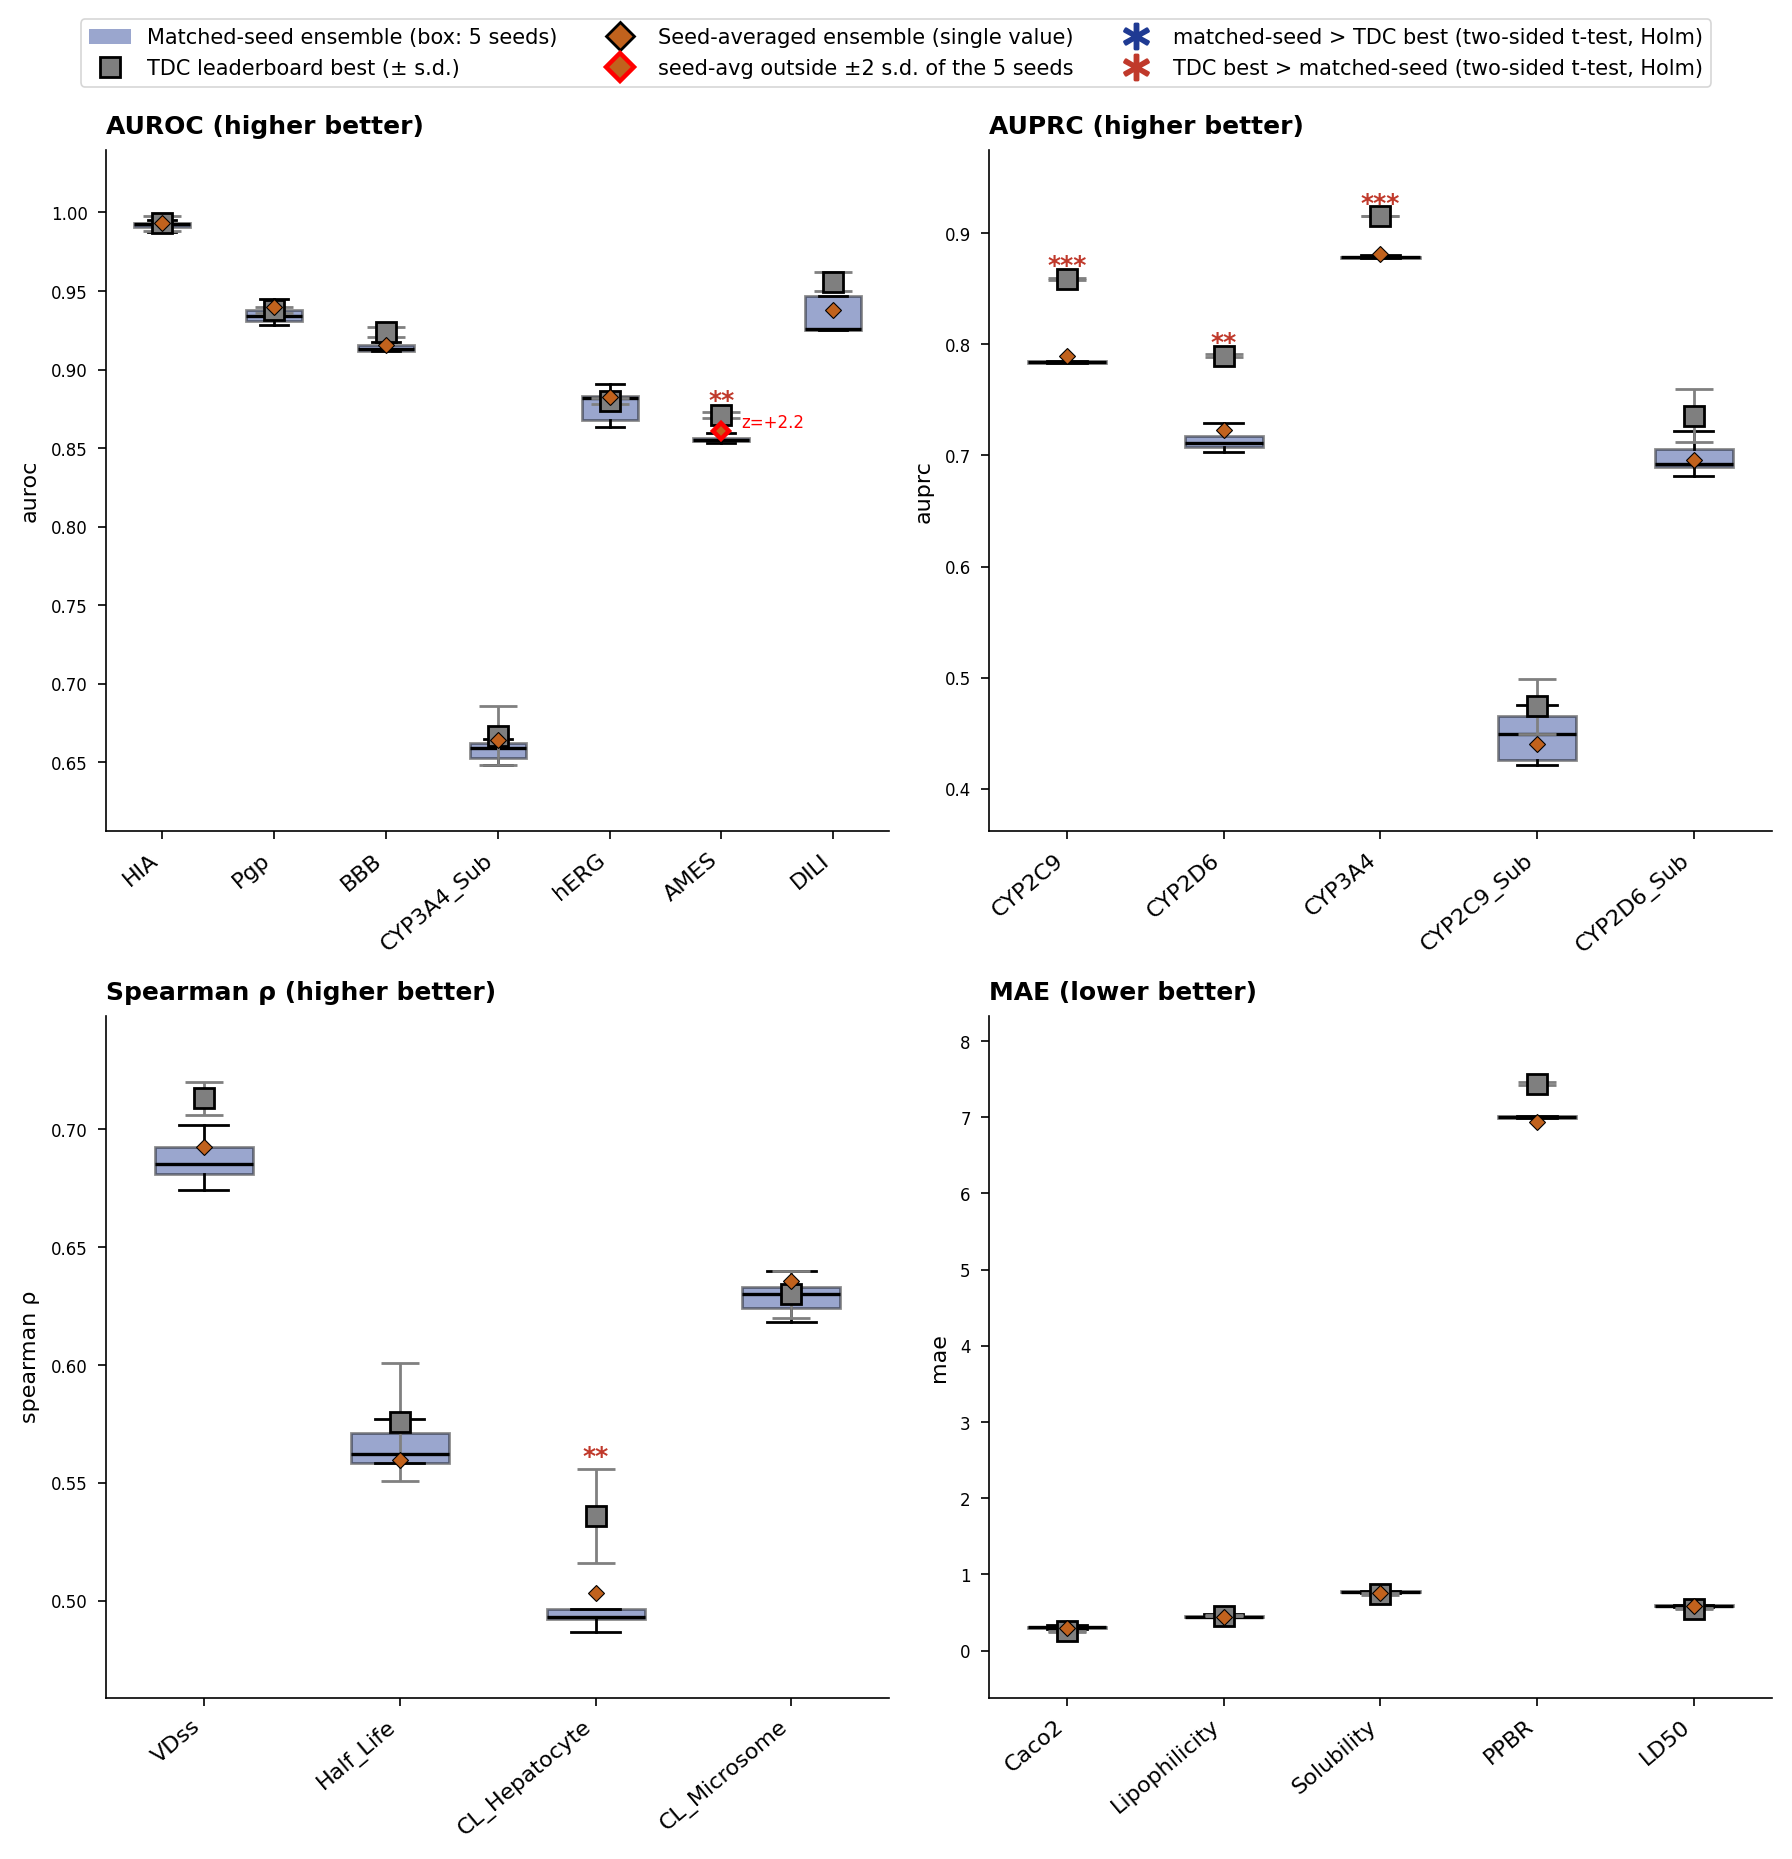

In [3]:
# === figureS6.png (Supplementary: per-task box plots vs TDC leaderboard best, faceted by metric) ===
# Per-task, three-way RAW-score comparison shown as box plots of the five matched-seed scores,
# overlaid with the TDC leaderboard best (grey square + s.d. error bar) and the seed-averaged
# ensemble (orange diamond, single pooled value). Two questions are answered per task:
#  (1) Is the matched-seed ensemble different from the TDC leaderboard best, and in which direction?
#      -> one-sample, TWO-sided t-test of the five per-seed scores against the fixed leaderboard
#         best value (df = 4, so power is limited). Stars use the Holm-adjusted p across all 21
#         tasks; the sign of the mean gap sets the colour: blue star = matched-seed > TDC best,
#         red star = TDC best > matched-seed.
#  (2) Does the seed-averaged value fall inside the matched-seed 5-seed distribution?
#      -> z = (seedavg - matched_mean)/matched_sd; |z| > 2 (outside ~95% of the seed spread)
#         is flagged with a ringed marker and the z value.
import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests
apply_figure_style(sizes=(8,7,6))

def _tdc_best(task):
    e=SNAP.get(task)
    if not e or not e.get("models"): return (None,None,None)
    md=e["models"]; direc=e.get("direction","higher")
    bm=(min if direc=="lower" else max)(md, key=lambda k: md[k]["score"])
    return bm, md[bm]["score"], md[bm].get("std")

# per-seed matched scores for every task (same recipe as table_t4: merge_uniform within, group by seed)
_bw = merge_uniform(ENSEMBLE, True)
def _seed_scores(task):
    met=REG[task]["metric"]
    tw=_bw[(_bw.task==task)&(_bw.split=="test")].dropna(subset=["y_true"])
    return met, np.array([metric(met, g.y_true, g.yhat) for _,g in tw.groupby("seed")], dtype=float)

recs=[]
for e in _t4e:
    t=e["task"]; met,seeds=_seed_scores(t)
    bm,bs,bstd=_tdc_best(t)
    if bs is None or len(seeds)<2: continue
    sign = -1.0 if met=="mae" else 1.0                    # + = better
    # (1) TWO-sided one-sample t-test: do the 5 seed scores differ from the fixed best?
    #     direction-aligned mean gap (+ = matched-seed better; - = TDC best better)
    tstat,p2 = ttest_1samp(sign*seeds, sign*bs)
    gap = float((sign*seeds).mean() - sign*bs)            # + matched better, - best better
    # (2) seed-avg position within the matched 5-seed distribution
    m_mean=float(seeds.mean()); m_sd=float(seeds.std(ddof=0)); sa=e["cross_score"]
    z = (sa-m_mean)/m_sd if m_sd>0 else 0.0
    recs.append(dict(task=t, metric=met, seeds=seeds, best=bs, best_sd=(bstd or 0.0),
                     seedavg=sa, m_mean=m_mean, m_sd=m_sd, p_raw=float(p2), gap=gap, z=z, tstat=tstat))
D=pd.DataFrame(recs); n=len(D)
# Holm across all 21 tasks (one-sided ensemble>best)
rej,pholm,_,_=multipletests(D.p_raw.to_numpy(), method="holm")
D["p_holm"]=pholm
def _stars(p): return "***" if p<1e-3 else "**" if p<1e-2 else "*" if p<0.05 else ""

SHORT={"Solubility_AqSolDB":"Solubility","Caco2_Wang":"Caco2","HIA_Hou":"HIA","Lipophilicity_AstraZeneca":"Lipophilicity",
 "PPBR_AZ":"PPBR","BBB_Martins":"BBB","VDss_Lombardo":"VDss","Pgp_Broccatelli":"Pgp","hERG":"hERG",
 "CYP2C9_Veith":"CYP2C9","CYP2D6_Veith":"CYP2D6","CYP3A4_Veith":"CYP3A4","CYP2C9_Substrate_CarbonMangels":"CYP2C9_Sub",
 "CYP2D6_Substrate_CarbonMangels":"CYP2D6_Sub","CYP3A4_Substrate_CarbonMangels":"CYP3A4_Sub",
 "Clearance_Hepatocyte_AZ":"CL_Hepatocyte","Clearance_Microsome_AZ":"CL_Microsome",
 "AMES":"AMES","DILI":"DILI","LD50_Zhu":"LD50","Half_Life_Obach":"Half_Life"}
FAC=[("auroc","AUROC (higher better)"),("auprc","AUPRC (higher better)"),
     ("spearman","Spearman \u03c1 (higher better)"),("mae","MAE (lower better)")]
COL_BEST="#7f7f7f"; COL_M="#1f3a93"; COL_S="#c1621d"

plt.close('all')
fig,axes=plt.subplots(2,2,figsize=(9,9))
for ax,(met,title) in zip(axes.ravel(),FAC):
    sub=D[D.metric==met].reset_index(drop=True); m=len(sub); x=np.arange(m)
    # matched-seed box plots (5 seeds each)
    bp=ax.boxplot([r.seeds for _,r in sub.iterrows()], positions=x, widths=0.5,
                  patch_artist=True, medianprops=dict(color="black",lw=1.2), showfliers=False)
    for patch in bp["boxes"]: patch.set_facecolor(COL_M); patch.set_alpha(0.45)
    # TDC best: grey square + sd error bar
    ax.errorbar(x-0.0, sub.best, yerr=sub.best_sd, fmt="s", color=COL_BEST, ms=7,
                capsize=7, elinewidth=1.0, ecolor="grey", mec="black", mew=1, zorder=6, label="TDC best")
    # seed-averaged: orange diamond; ring if |z|>2 (outside 5-seed distribution)
    for xi,(_,r) in zip(x,sub.iterrows()):
        out = abs(r.z)>2
        ax.plot(xi, r.seedavg, marker="D", ms=4, color=COL_S,
                mec=("red" if out else "black"), mew=(1.6 if out else 0.4), zorder=7)
        if out: ax.annotate(f"z={r.z:+.1f}", (xi,r.seedavg), textcoords="offset points",
                            xytext=(7,3), fontsize=6.0, color="red", va="center")
    # significance stars (matched vs TDC best), coloured by direction of the gap
    for xi,(_,r) in zip(x,sub.iterrows()):
        st=_stars(r.p_holm)
        if st:
            top=max(r.seeds.max(), r.best+r.best_sd, r.seedavg)
            scol = COL_M if r.gap>0 else "#c0392b"       # blue: matched>best ; red: best>matched
            ax.text(xi, top, st, ha="center", va="bottom", fontsize=9, color=scol, fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels([SHORT[t] for t in sub.task],rotation=40,ha="right",fontsize=8)
    ax.set_title(title,loc="left",fontweight="bold",fontsize=9)
    ax.set_ylabel(met if met!="spearman" else "spearman \u03c1",fontsize=8)
    ax.margins(x=0.04, y=0.12)

handles=[Patch(facecolor=COL_M,alpha=0.45,label="Matched-seed ensemble (box: 5 seeds)"),
         Line2D([0],[0],marker="s",color="none",mfc=COL_BEST,mec="black",ms=7,label="TDC leaderboard best (\u00b1 s.d.)"),
         Line2D([0],[0],marker="D",color="none",mfc=COL_S,mec="black",ms=7,label="Seed-averaged ensemble (single value)"),
         Line2D([0],[0],marker="D",color="none",mfc=COL_S,mec="red",mew=1.6,ms=7,label="seed-avg outside \u00b12 s.d. of the 5 seeds"),
         Line2D([0],[0],marker="$*$",color=COL_M,ms=9,lw=0,label="matched-seed > TDC best (two-sided t-test, Holm)"),
         Line2D([0],[0],marker="$*$",color="#c0392b",ms=9,lw=0,label="TDC best > matched-seed (two-sided t-test, Holm)")]
fig.legend(handles=handles,loc="upper center",ncol=3,fontsize=7.5,frameon=True,bbox_to_anchor=(0.5,1.03))
# fig.suptitle("Per-task matched-seed ensemble vs TDC leaderboard best, with seed-averaged position",
#              fontweight="bold",fontsize=10,y=1.06)
fig.tight_layout(rect=[0,0,1,0.985])
fig.savefig(os.path.join(OUTDIR,"figureS6.png"),dpi=300,bbox_inches="tight")
assert n==21
_sig=D[D.p_holm<0.05]
_blue=list(_sig[_sig.gap>0].task); _red=list(_sig[_sig.gap<0].task); _nout=int((D.z.abs()>2).sum())
print("figureS6.png written | sig tasks (Holm p<0.05):", len(_sig), "/21",
      "| matched>best (blue):", len(_blue), "| best>matched (red):", len(_red),
      "| seed-avg outside ±2sd:", _nout)
print("blue (matched>best):", _blue)
print("red  (best>matched):", _red)
plt.show()


*Figure S6. Per-task raw held-out-test scores across the 21 TDC ADMET tasks, grouped into one panel per metric family (AUROC, AUPRC, Spearman ρ — higher is better; MAE — lower is better). For each task the box shows the five matched-seed ensemble scores (blue); the grey square with error bar is the TDC leaderboard best model (score ± s.d. from the leaderboard snapshot); the orange diamond is the seed-averaged ensemble (single pooled value, no seed-level s.d.). Two questions are annotated. (1) Whether the matched-seed ensemble differs from the leaderboard best is tested with a one-sample, two-sided t-test of the five per-seed scores against the fixed leaderboard-best value (df = 4, so power is limited); asterisks (*, **, *** at p < 0.05, 0.01, 0.001) use the Holm-adjusted p across all 21 tasks and are coloured by direction — blue when the matched-seed ensemble exceeds the leaderboard best, red when the leaderboard best exceeds the matched-seed ensemble. (2) Whether the seed-averaged value falls inside the matched-seed distribution is summarised by z = (seed-averaged − matched mean)/matched s.d.; a red-ringed diamond with its z value flags |z| > 2 (outside roughly the central 95% of the five-seed spread). The same scores, with leaderboard ranks, are listed in Table 5.*

## Fig. S7 (Supplementary) — Leaderboard coverage versus mean rank

figureS7.png written | distinct models 41 | full-21 models 14 | Tetra-Fuse mean rank 3.95 | full-cov models better than Tetra-Fuse: ['MapLight + GNN']


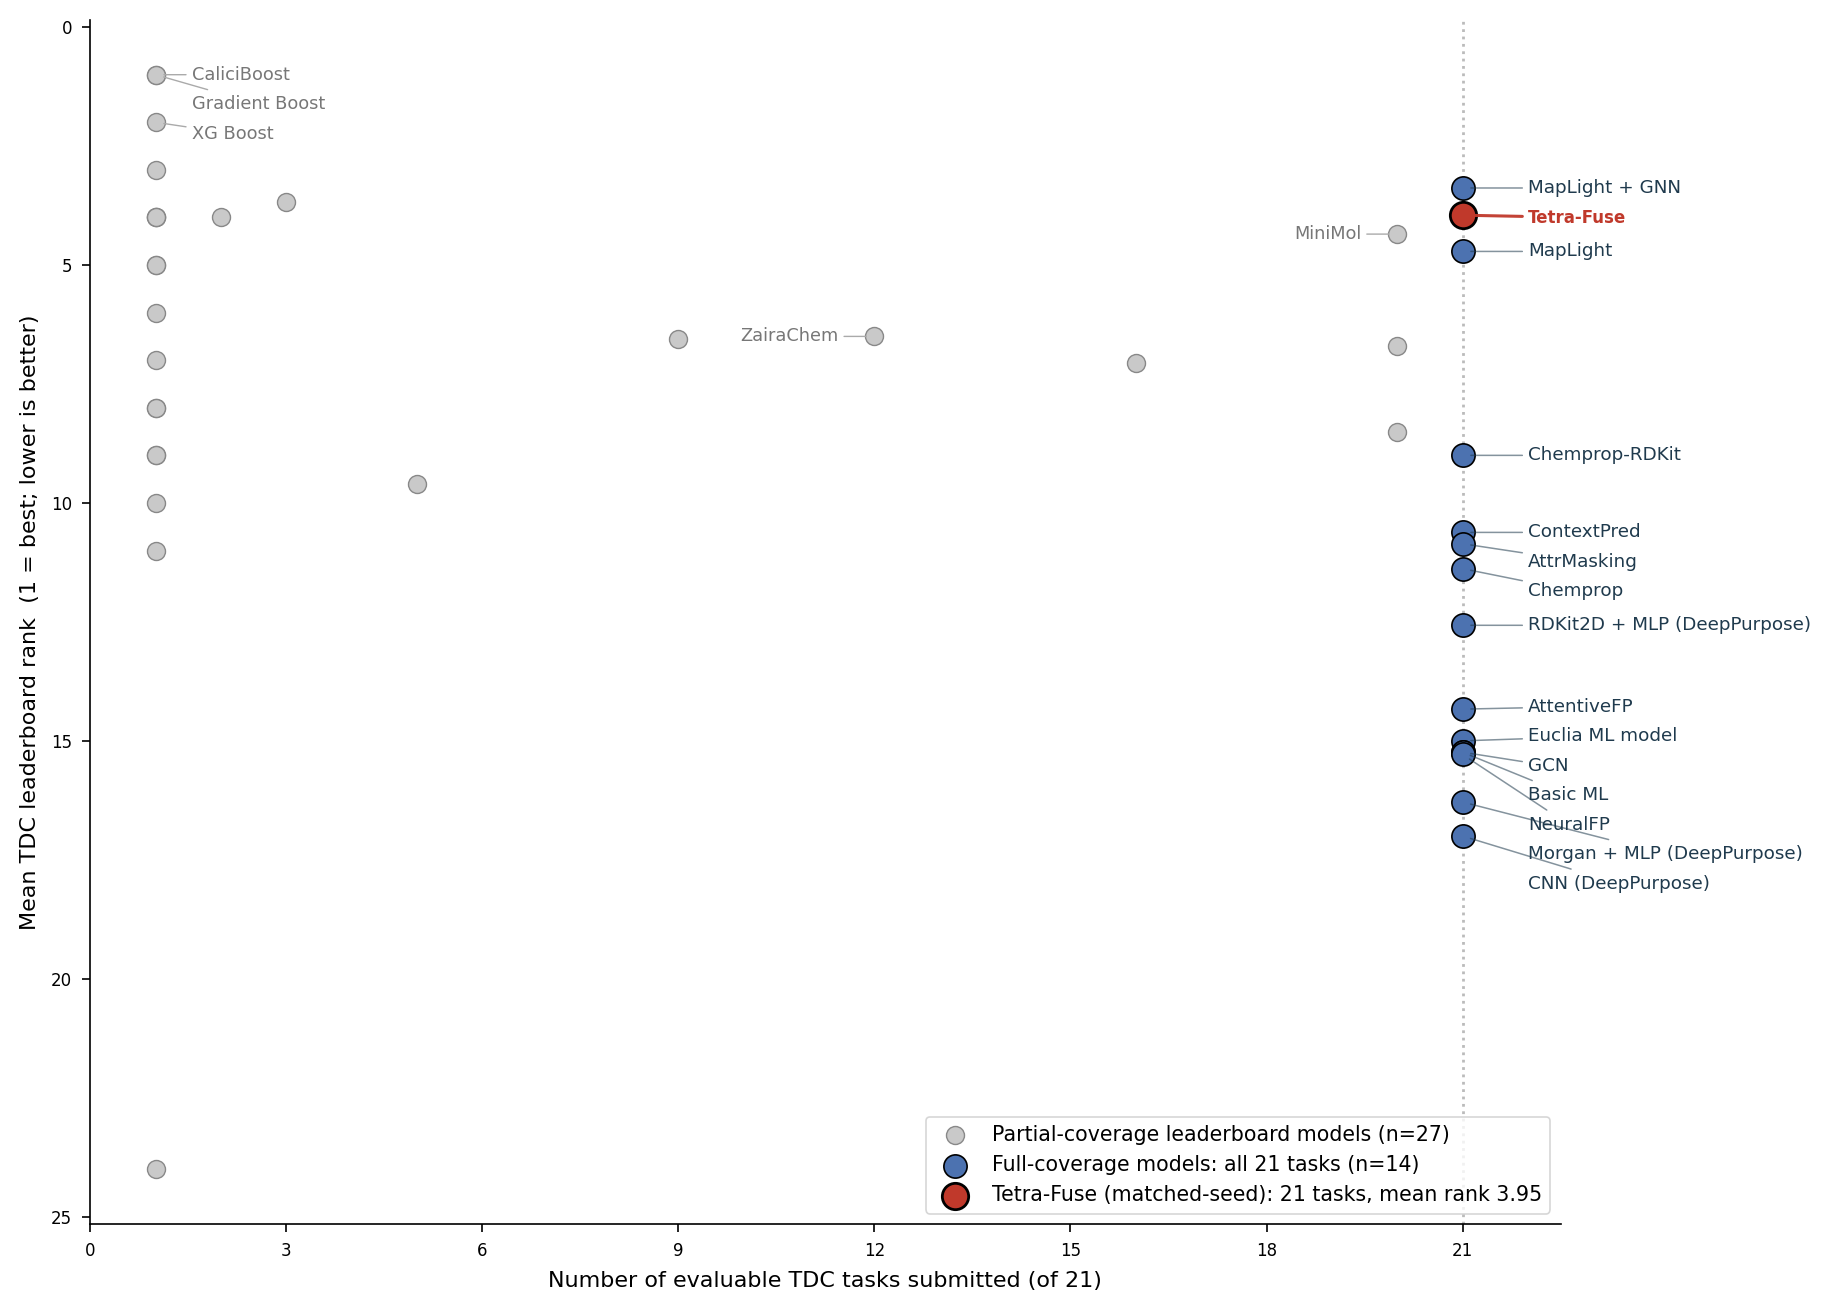

In [4]:
# === figureS7.png (Supplementary: leaderboard coverage vs mean rank) ===
# How the final Tetra-Fuse ensemble compares to every other model on the TDC ADMET leaderboard
# in terms of BREADTH (how many of the 21 evaluable tasks a model submitted to) and DEPTH
# (its mean leaderboard rank over the tasks it entered). Many leaderboard models submit to only
# a handful of tasks, which can give a deceptively low mean rank; a fair comparison must read
# coverage and mean rank together. Bioavailability_Ma is excluded (21 evaluable tasks).
import numpy as np, matplotlib.pyplot as plt
from collections import defaultdict
from matplotlib.ticker import MaxNLocator
apply_figure_style(sizes=(8,7,6))

# 21 evaluable tasks (skip the _timestamp metadata key and Bioavailability_Ma)
EVAL=[t for t,v in SNAP.items() if isinstance(v,dict) and "models" in v and t!="Bioavailability_Ma"]
assert len(EVAL)==21, len(EVAL)
def _ranks(task):
    e=SNAP[task]; md=e["models"]; direc=e.get("direction","higher")
    items=[(m,v["score"]) for m,v in md.items()]
    return {m: sum(1 for _,s2 in items if (s2<s if direc=="lower" else s2>s))+1 for m,s in items}
mr=defaultdict(list)
for t in EVAL:
    for m,rk in _ranks(t).items(): mr[m].append(rk)
lb=pd.DataFrame([(m,len(v),float(np.mean(v))) for m,v in mr.items()],
                columns=["model","n_tasks","mean_rank"]).sort_values(["mean_rank","n_tasks"]).reset_index(drop=True)

# Tetra-Fuse: matched-seed mean rank over the 21 evaluable tasks (from _PT["t4"], excl Bioavailability_Ma)
tetra_ranks=[e["within_rank"] for e in _t4e if e["task"]!="Bioavailability_Ma"]
assert len(tetra_ranks)==21
TETRA_N=21; TETRA_MR=float(np.mean(tetra_ranks))

plt.close('all')
fig,ax=plt.subplots(figsize=(9.2,6.6))
# split partial- vs full-coverage leaderboard models
full=lb[lb.n_tasks==21]; part=lb[lb.n_tasks<21]
ax.scatter(part.n_tasks, part.mean_rank, s=42, facecolor="#c9c9c9", edgecolor="#888", lw=0.5,
           zorder=3, label=f"Partial-coverage leaderboard models (n={len(part)})")
ax.scatter(full.n_tasks, full.mean_rank, s=70, facecolor="#4c72b0", edgecolor="black", lw=0.6,
           zorder=4, label=f"Full-coverage models: all 21 tasks (n={len(full)})")
# Tetra-Fuse star
ax.scatter([TETRA_N],[TETRA_MR], s=90, marker="o", color="#c0392b", edgecolor="black", lw=1,
           zorder=6, label=f"Tetra-Fuse (matched-seed): 21 tasks, mean rank {TETRA_MR:.2f}")
ax.invert_yaxis()   # rank 1 (best) at the top
ax.set_xlabel("Number of evaluable TDC tasks submitted (of 21)")
ax.set_ylabel("Mean TDC leaderboard rank  (1 = best; lower is better)")
# ax.set_title("Leaderboard breadth vs mean rank: Tetra-Fuse covers all 21 tasks at a top-tier mean rank",
#              loc="left", fontweight="bold", fontsize=9)
ax.axvline(21, color="#bbb", ls=":", lw=1, zorder=1)

# ── 겹침 없는 라벨 배치: 전용 라벨 컬럼 + 자동 수직 분산 + 리더선 ──────────────
def _spread(ys, min_gap, lo, hi):
    """ys를 원래 순서 유지한 채 최소 간격 min_gap 이상으로 벌림 (lo~hi 범위 내)."""
    order = np.argsort(ys)
    v = np.array(ys, float)[order]
    # 1차: 아래에서 위로 밀기
    for i in range(1, len(v)):
        if v[i] - v[i-1] < min_gap:
            v[i] = v[i-1] + min_gap
    # 2차: 상한 초과분을 위에서 아래로 되밀기
    if len(v) and v[-1] > hi:
        v[-1] = hi
        for i in range(len(v)-2, -1, -1):
            if v[i+1] - v[i] < min_gap:
                v[i] = v[i+1] - min_gap
    v = np.clip(v, lo, hi)
    out = np.empty_like(v)
    out[order] = v
    return out

LAB_X = 22.0          # 라벨 컬럼 x 위치 (축 우측 여백)
ax.set_xlim(0, 26.5)  # 라벨 컬럼을 담을 여백 확보

# --- 1) full-coverage(x=21) + Tetra-Fuse: 우측 라벨 컬럼에 일괄 배치 ---
right = [(rw.n_tasks, rw.mean_rank, rw.model, "#1f3a4d", 6.6, False)
         for _, rw in full.iterrows()]
right.append((TETRA_N, TETRA_MR, "Tetra-Fuse", "#c0392b", 6.0, True))
right.sort(key=lambda t: t[1])                      # 순위(=y) 오름차순

ys_r = _spread([t[1] for t in right], min_gap=0.62,
               lo=min(t[1] for t in right) - 1.0,
               hi=max(t[1] for t in right) + 1.0)

for (x, y, txt, col, fs, is_star), ty in zip(right, ys_r):
    ax.annotate(
        txt, xy=(x, y), xytext=(LAB_X, ty),
        textcoords="data", ha="left", va="center",
        fontsize=fs, color=col, fontweight="bold" if is_star else "normal",
        zorder=8,
        arrowprops=dict(arrowstyle="-", color=col,
                        lw=1.1 if is_star else 0.55,
                        alpha=0.95 if is_star else 0.55,
                        shrinkA=0, shrinkB=3,
                        connectionstyle="arc3,rad=0"),
    )

# --- 2) partial-coverage 주석 대상: 마커 왼쪽에 배치해 우측 컬럼과 분리 ---
# --- 2) partial-coverage 주석 대상 ---
_partnames_right = ["CaliciBoost", "Gradient Boost", "XG Boost"]   # 마커 오른쪽
_partnames_left  = ["MiniMol", "ZairaChem"]                        # 마커 왼쪽

def _collect(names):
    out = [(part[part.model == n].iloc[0].n_tasks,
            part[part.model == n].iloc[0].mean_rank, n)
           for n in names if n in set(part.model)]
    out.sort(key=lambda t: t[1])
    return out

def _draw(items, side):
    if not items:
        return
    ys = _spread([t[1] for t in items], min_gap=0.62,
                 lo=min(t[1] for t in items) - 1.0,
                 hi=max(t[1] for t in items) + 1.0)
    for (x, y, txt), ty in zip(items, ys):
        dx, ha = (0.55, "left") if side == "right" else (-0.55, "right")
        ax.annotate(
            txt, xy=(x, y), xytext=(x + dx, ty),
            textcoords="data", ha=ha, va="center",
            fontsize=6.4, color="#777", zorder=8,
            arrowprops=dict(arrowstyle="-", color="#aaa", lw=0.5,
                            shrinkA=0, shrinkB=3),
        )

_draw(_collect(_partnames_right), "right")
_draw(_collect(_partnames_left),  "left")

ax.legend(loc="lower right", fontsize=7.4, frameon=True)
ax.set_xlim(0,22.5)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))   # ← 이 줄 추가
fig.tight_layout()
fig.savefig(os.path.join(OUTDIR,"figureS7.png"),dpi=300,bbox_inches="tight")
# checks: 14 full-coverage models; among them only MapLight+GNN beats Tetra-Fuse mean rank
n_full=int((lb.n_tasks==21).sum())
beat=list(full[full.mean_rank<TETRA_MR].model)
print("figureS7.png written | distinct models", len(lb), "| full-21 models", n_full,
      "| Tetra-Fuse mean rank", round(TETRA_MR,2), "| full-cov models better than Tetra-Fuse:", beat)
assert abs(TETRA_MR-3.95)<0.02, TETRA_MR
plt.show()


*Figure S7. Breadth–depth view of the TDC ADMET leaderboard over the 21 evaluable tasks (Bioavailability_Ma excluded). Each point is a leaderboard model, positioned by the number of tasks it submitted to (x-axis) and its mean leaderboard rank over those tasks (y-axis, inverted so rank 1 is at the top). Grey points are partial-coverage models — many attain a low mean rank only because they entered one or a few tasks — while blue points are the models that submitted to all 21 tasks. The red star is our final Tetra-Fuse ensemble (matched-seed track): it covers all 21 tasks at a mean rank of 3.95, second only to MapLight + GNN (3.38) among full-coverage models. This shows that Tetra-Fuse's strength is uniform breadth at a top-tier rank, not a low mean rank bought by narrow task coverage.*

In [5]:
# --- Table 5: per-task held-out-test performance of the final k=5 ensemble (21 tasks) ---
# Prespecified primary test evaluation, straight from _PT["t4"]. Bioavailability_Ma excluded.
# Column order (as laid out for the manuscript): Task, Metric, the TDC leaderboard best model
# and its score, then our matched-seed and seed-averaged results with leaderboard ranks.
# Matched score = mean ± s.d. over the five seeds (per-seed scoring, ddof=0, TDC ours_std
# convention). The seed-averaged track pools the five seeds into one prediction vector scored
# once, so it has no seed-level s.d. (single value).
# TDC leaderboard best model / score come from the frozen snapshot ruler
# (tdc_leaderboard_snapshot.json), chosen direction-aware (auroc/auprc/spearman -> max, mae -> min);
# the best score is shown as score ± s.d. using that model's leaderboard s.d.
def _tdc_best(task):
    e=SNAP.get(task)
    if not e or not e.get("models"): return ("\u2014", None, None)
    md=e["models"]; direc=e.get("direction","higher")
    bm=(min if direc=="lower" else max)(md, key=lambda k: md[k]["score"])
    return bm, md[bm].get("score"), md[bm].get("std")
T4_rows=[]
for e in _t4e:
    matched=f'{e["within_score"]:.3f} ± {e["within_std"]:.3f}'
    bm,bs,bstd=_tdc_best(e["task"])
    if bs is None: best_str="\u2014"
    elif bstd is None: best_str=f"{bs:.3f}"
    else: best_str=f"{bs:.3f} ± {bstd:.3f}"
    T4_rows.append([e["task"], e["metric"], bm, best_str,
                    matched, int(e["within_rank"]),
                    round(e["cross_score"],3), int(e["cross_rank"])])
T4=pd.DataFrame(T4_rows, columns=["Task","Metric","TDC leaderboard best model","TDC leaderboard best score",
    "Matched score (mean ± s.d.)","Matched rank","Seed-avg score","Seed-avg rank"])
register("table5_ensemble_pertask", T4)
assert len(T4)==21 and T4.iloc[0]["Task"]=="HIA_Hou" and T4.shape[1]==8
assert T4.iloc[0]["TDC leaderboard best model"]=="MiniMol" and T4.iloc[0]["TDC leaderboard best score"]=="0.993 ± 0.005", T4.iloc[0].to_dict()
assert T4.iloc[0]["Matched score (mean ± s.d.)"].startswith("0.992 ±")
print("Table 5 OK", T4.shape, "| cols:", list(T4.columns)); T4.head(4)


Table 5 OK (21, 8) | cols: ['Task', 'Metric', 'TDC leaderboard best model', 'TDC leaderboard best score', 'Matched score (mean ± s.d.)', 'Matched rank', 'Seed-avg score', 'Seed-avg rank']


,Task,Metric,TDC leaderboard best model,TDC leaderboard best score,Matched score (mean ± s.d.),Matched rank,Seed-avg score,Seed-avg rank
0,HIA_Hou,auroc,MiniMol,0.993 ± 0.005,0.992 ± 0.003,2,0.993,1
1,Pgp_Broccatelli,auroc,MapLight + GNN,0.938 ± 0.002,0.935 ± 0.006,2,0.940,1
2,BBB_Martins,auroc,MiniMol,0.924 ± 0.003,0.913 ± 0.004,6,0.915,4
3,CYP2C9_Veith,auprc,MapLight + GNN,0.859 ± 0.001,0.785 ± 0.005,7,0.790,5


*Table 5. Per-task held-out-test performance of the final k = 5 ensemble across the 21 TDC ADMET tasks. For each task we list the metric and the current TDC leaderboard best model with its published score (mean ± s.d. from the leaderboard snapshot), then our ensemble's matched-seed score (mean ± s.d. over the five seeds, per-seed scoring, the TDC convention) with its leaderboard rank, and the seed-averaged score with its rank; the seed-averaged track pools the five-seed predictions into a single prediction scored once, so it carries no seed-level s.d. by construction. Bioavailability_Ma is excluded.*

## Table S8 — Ensemble vs baseline significance (8 prespecified comparisons)

Mean/median Δnorm_score, win/tie/loss, one-sided paired Wilcoxon statistic, raw and Holm-corrected p, for the k=5 late-fusion ensemble against three deployable single models and the per-task oracle, on both tracks. These are the values plotted in Figure 5.

In [6]:
# --- Table S8: ensemble vs baseline significance (8 prespecified comparisons, both tracks) ---
# Self-contained: recomputes the one-sided paired Wilcoxon statistics (over 21 per-task norm_scores,
# Holm-corrected across all eight comparisons) directly here, so this cell does not depend on the
# figure4 cell's `_FIG4_STATS`. Same numbers plotted in Figure 5. Basis: matched-seed (within) /
# seed-averaged (cross) per-task norm from _SOLO_PT and the k=5 ensemble from _PT["t4"].
import numpy as np
from scipy.stats import wilcoxon

_t4  = {e["task"]: e for e in _PT["t4"] if e["task"] != "Bioavailability_Ma"}
_solo = _SOLO_PT
_models = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer","mtl_map",
           "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer","stl_map"]
_tasks = sorted(t for t in _solo.task.unique() if t in _t4)
_pw = {m: _solo[_solo.model==m].set_index("task")["within_norm"] for m in _models}
_pc = {m: _solo[_solo.model==m].set_index("task")["cross_norm"]  for m in _models}
_ens_w = np.array([_t4[d]["within_norm"] for d in _tasks])
_ens_c = np.array([_t4[d]["cross_norm"]  for d in _tasks])
_best_w = np.array([max(_pw[m][d] for m in _models) for d in _tasks])   # per-task oracle (matched-seed)
_best_c = np.array([max(_pc[m][d] for m in _models) for d in _tasks])   # per-task oracle (seed-averaged)

def _ptn(model, track): 
    piv = _pw if track=="within" else _pc
    return np.array([piv[model][d] for d in _tasks])

_res={}
for bn,bm in [("CheMeleon·STL","stl_chemeleon"),("MAP·STL","stl_map"),("D-MPNN·MTL","mtl_dmpnn")]:
    for track,ens in [("within",_ens_w),("cross",_ens_c)]:
        b=_ptn(bm,track); diff=ens-b
        stat,p=wilcoxon(ens,b,alternative="greater")
        w=int((diff>1e-9).sum()); t=int((abs(diff)<=1e-9).sum()); l=int((diff<-1e-9).sum())
        _res[(bn,track)]=dict(median=float(np.median(diff)),mean=float(diff.mean()),W=float(stat),p=float(p),
                              wtl=f"{w}/{t}/{l}",base_mean=float(b.mean()),ens_mean=float(ens.mean()))
_orc={}
for track,ens,bt in [("within",_ens_w,_best_w),("cross",_ens_c,_best_c)]:
    diff=ens-bt; stat,p=wilcoxon(ens,bt,alternative="greater")
    w=int((diff>1e-9).sum()); t=int((abs(diff)<=1e-9).sum()); l=int((diff<-1e-9).sum())
    _orc[track]=dict(median=float(np.median(diff)),mean=float(diff.mean()),W=float(stat),p=float(p),
                     wtl=f"{w}/{t}/{l}",base_mean=float(bt.mean()),ens_mean=float(ens.mean()))
_order=[("CheMeleon·STL","within"),("CheMeleon·STL","cross"),("MAP·STL","within"),("MAP·STL","cross"),
        ("D-MPNN·MTL","within"),("D-MPNN·MTL","cross"),("per-task oracle","within"),("per-task oracle","cross")]
_rows=[(_orc[tr] if base=="per-task oracle" else _res[(base,tr)]) | {"base":base,"track":tr} for base,tr in _order]
# Holm across all 8 comparisons
_p=np.asarray([rw["p"] for rw in _rows],float); _o=np.argsort(_p); _mm=len(_p); _holm=np.empty(_mm); _prev=0.0
for _rk,_ix in enumerate(_o):
    _v=(_mm-_rk)*_p[_ix]; _prev=max(_prev,_v); _holm[_ix]=min(_prev,1.0)
for rw,hp in zip(_rows,_holm): rw["p_holm"]=float(hp)

_trk={"within":"matched-seed","cross":"seed-averaged"}
rows=[]
for rw in _rows:
    rows.append([rw["base"], _trk[rw["track"]],
        round(rw["base_mean"],4), round(rw["ens_mean"],4), round(rw["mean"],4), round(rw["median"],4),
        rw["wtl"], round(rw["W"],1), f"{rw['p']:.2e}", f"{rw['p_holm']:.2e}",
        "***" if rw["p_holm"]<0.001 else "**" if rw["p_holm"]<0.01 else "*" if rw["p_holm"]<0.05 else "n.s."])
cols=["Baseline","Track","Baseline norm_score","Ensemble norm_score","Mean Δ","Median Δ",
      "Wins/ties/losses","Wilcoxon W","p (raw)","p (Holm)","Significance"]
S8=pd.DataFrame(rows,columns=cols)
register("tableS8_ensemble_vs_baselines", S8)
_dep=S8[S8.Baseline!="per-task oracle"]
assert (_dep["Significance"]!="n.s.").all(), _dep.to_dict("records")
assert len(S8)==8 and S8["Ensemble norm_score"].nunique()<=2
print("S8 OK (self-contained)", S8.shape); S8


S8 OK (self-contained) (8, 11)


,Baseline,Track,Baseline norm_score,Ensemble norm_score,Mean Δ,Median Δ,Wins/ties/losses,Wilcoxon W,p (raw),p (Holm),Significance
0,CheMeleon·STL,matched-seed,0.6331,0.8540,0.2209,0.2000,20/0/1,226.0,6.12e-05,4.90e-04,***
1,CheMeleon·STL,seed-averaged,0.7298,0.8971,0.1673,0.1500,17/2/2,178.0,4.17e-04,1.67e-03,**
2,MAP·STL,matched-seed,0.6045,0.8540,0.2495,0.2633,20/0/1,225.0,7.04e-05,4.93e-04,***
3,MAP·STL,seed-averaged,0.7745,0.8971,0.1226,0.1000,14/4/3,139.0,1.55e-03,4.64e-03,**
4,D-MPNN·MTL,matched-seed,0.6047,0.8540,0.2493,0.2779,17/3/1,169.0,1.38e-04,8.29e-04,***
5,D-MPNN·MTL,seed-averaged,0.6851,0.8971,0.2120,0.1578,16/3/2,164.0,3.14e-04,1.57e-03,**
6,per-task oracle,matched-seed,0.8110,0.8540,0.0430,0.0420,14/3/4,129.0,2.91e-02,5.81e-02,n.s.
7,per-task oracle,seed-averaged,0.9318,0.8971,-0.0347,0.0000,2/9/10,8.0,9.92e-01,9.92e-01,n.s.


## Figure 5. Tetra-Fuse versus deployable single models.


saved figure5.png (single panel); 8 comparisons


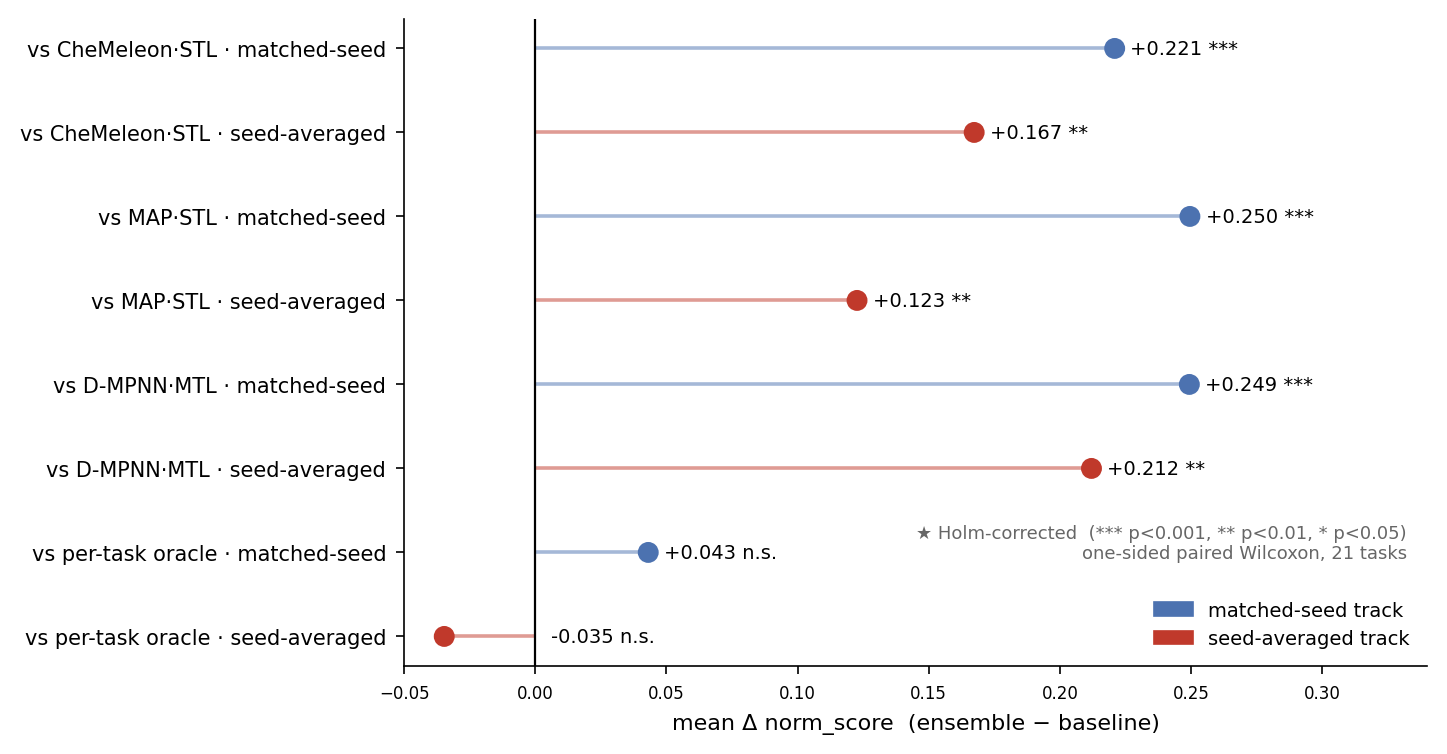

In [7]:
# === figure5.png (statistical significance of the ensemble gain — single forest panel) ===
import json
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import wilcoxon

apply_figure_style(sizes=(8, 7, 6))
GT = _GT; PT = _PT

# Single-model per-task norm on the SAME matched-seed(within)/seed-averaged(cross) basis as
# Table 4 and the ensemble (t4). _SOLO_PT (recomputed) provides both tracks consistently.
t4 = {e["task"]: e for e in PT["t4"] if e["task"] != "Bioavailability_Ma"}
_solo = _SOLO_PT
models = ["mtl_dmpnn", "mtl_chemeleon", "mtl_graphmvp", "mtl_molformer", "mtl_map",
          "stl_dmpnn", "stl_chemeleon", "stl_graphmvp", "stl_molformer", "stl_map"]
tasks = sorted(t for t in _solo.task.unique() if t in t4)
_piv_w = {m: _solo[_solo.model == m].set_index("task")["within_norm"] for m in models}
_piv_c = {m: _solo[_solo.model == m].set_index("task")["cross_norm"] for m in models}
ens_w = np.array([t4[d]["within_norm"] for d in tasks])
ens_c = np.array([t4[d]["cross_norm"] for d in tasks])
best_w = np.array([max(_piv_w[m][d] for m in models) for d in tasks])   # per-task oracle best single (matched-seed)
best_c = np.array([max(_piv_c[m][d] for m in models) for d in tasks])   # per-task oracle best single (seed-averaged)

def per_task_norm(model, track="within"):
    piv = _piv_w if track == "within" else _piv_c
    return np.array([piv[model][d] for d in tasks])

# --- eight prespecified comparisons: 3 deployable single models x 2 tracks + per-task oracle x 2 tracks ---
results = {}
for base_name, base_model in [("CheMeleon·STL", "stl_chemeleon"), ("MAP·STL", "stl_map"), ("D-MPNN·MTL", "mtl_dmpnn")]:
    for track, ens in [("within", ens_w), ("cross", ens_c)]:
        b = per_task_norm(base_model, track)
        diff = ens - b
        stat, p = wilcoxon(ens, b, alternative="greater")
        wins = int((diff > 1e-9).sum()); ties = int((abs(diff) <= 1e-9).sum()); losses = int((diff < -1e-9).sum())
        results[(base_name, track)] = dict(median=float(np.median(diff)), mean=float(diff.mean()),
                                           W=float(stat), p=float(p), wtl=f"{wins}/{ties}/{losses}",
                                           base_mean=float(b.mean()), ens_mean=float(ens.mean()))
oracle = {}
for track, ens, best_t in [("within", ens_w, best_w), ("cross", ens_c, best_c)]:
    diff = ens - best_t
    stat, p = wilcoxon(ens, best_t, alternative="greater")
    wins = int((diff > 1e-9).sum()); ties = int((abs(diff) <= 1e-9).sum()); losses = int((diff < -1e-9).sum())
    oracle[track] = dict(median=float(np.median(diff)), mean=float(diff.mean()),
                         W=float(stat), p=float(p), wtl=f"{wins}/{ties}/{losses}",
                         base_mean=float(best_t.mean()), ens_mean=float(ens.mean()))

# --- assemble ordered list + Holm-Bonferroni across all 8 prespecified comparisons ---
order = [("CheMeleon·STL", "within"), ("CheMeleon·STL", "cross"),
         ("MAP·STL", "within"), ("MAP·STL", "cross"),
         ("D-MPNN·MTL", "within"), ("D-MPNN·MTL", "cross"),
         ("per-task oracle", "within"), ("per-task oracle", "cross")]
rows = [ (oracle[tr] if base == "per-task oracle" else results[(base, tr)]) | {"base": base, "track": tr}
         for base, tr in order ]
_p = np.asarray([rw["p"] for rw in rows], float)
_ord = np.argsort(_p); _m = len(_p); _holm = np.empty(_m); _prev = 0.0
for _rank, _idx in enumerate(_ord):
    _val = (_m - _rank) * _p[_idx]; _prev = max(_prev, _val); _holm[_idx] = min(_prev, 1.0)
for rw, hp in zip(rows, _holm): rw["p_holm"] = float(hp)
_FIG4_STATS = rows   # per-comparison stats for the forest plot below

# --- single-panel forest plot: mean Δ norm_score with Holm-corrected significance ---
labels = [f"vs {rw['base']} · {'matched-seed' if rw['track']=='within' else 'seed-averaged'}" for rw in rows]
meds   = [rw["mean"] for rw in rows]
cols   = ["#c0392b" if rw["track"] == "cross" else "#4c72b0" for rw in rows]
stars  = ["***" if rw["p_holm"] < 0.001 else "**" if rw["p_holm"] < 0.01 else "*" if rw["p_holm"] < 0.05 else "n.s." for rw in rows]

plt.close('all')
fig, ax = plt.subplots(figsize=(6.6, 4.2))
y = np.arange(len(labels))[::-1]
ax.scatter(meds, y, s=48, color=cols, zorder=3)
ax.hlines(y, 0, meds, color=cols, lw=1.3, alpha=0.5)
ax.axvline(0, color="black", lw=0.8)
for yi, m_, st in zip(y, meds, stars):
    ax.text(max(m_, 0.0) + 0.006, yi, f"{m_:+.3f} {st}", va="center", fontsize=7)
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=7.5)
ax.set_xlabel("mean Δ norm_score  (ensemble − baseline)")
ax.set_xlim(-0.05, 0.34)
# ax.set_title("k=5 late-fusion gain is significant vs three strong deployable single models",
#              loc="left", fontweight="bold", fontsize=9.5)
ax.legend(handles=[Patch(color="#4c72b0", label="matched-seed track"),
                   Patch(color="#c0392b", label="seed-averaged track")],
          loc="lower right", bbox_to_anchor=(1.0,0), fontsize=7, frameon=False)
ax.text(0.98, 0.16, "★ Holm-corrected  (*** p<0.001, ** p<0.01, * p<0.05)\none-sided paired Wilcoxon, 21 tasks",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=6.5, color="#666")
fig.savefig(os.path.join(OUTDIR, "figure5.png"), dpi=300, bbox_inches="tight")
print("saved figure5.png (single panel);", len(_FIG4_STATS), "comparisons")


*Figure 5. Tetra-Fuse versus deployable single models. Mean Δnorm_score (Tetra-Fuse − baseline) for each deployable single-model baseline (CheMeleon·STL, MAP·STL, D-MPNN·MTL) and evaluation track, with one-sided paired Wilcoxon significance (Holm-corrected across eight comparisons; *** p < 0.001, * p < 0.01, n.s. not significant). The per-task oracle selects the best individual model per task using test labels and is a non-deployable reference.*


## Fig. S8 (Supplementary) — Homogeneous-ensemble control (Table S9)

figureS8.png + tableS9_homogeneous_control written | heterogeneous (matched-seed) 0.8539 | controls: CheMeleon·STL 0.730 (Holm p=0.0049), D-MPNN·MTL 0.685 (Holm p=0.0032), MoLFormer·MTL 0.644 (Holm p=0.0034), GraphMVP·STL 0.524 (Holm p=0.0003) | excluded MAP·STL five-seed reference 0.774 | mean 5-seed interval width 0.190


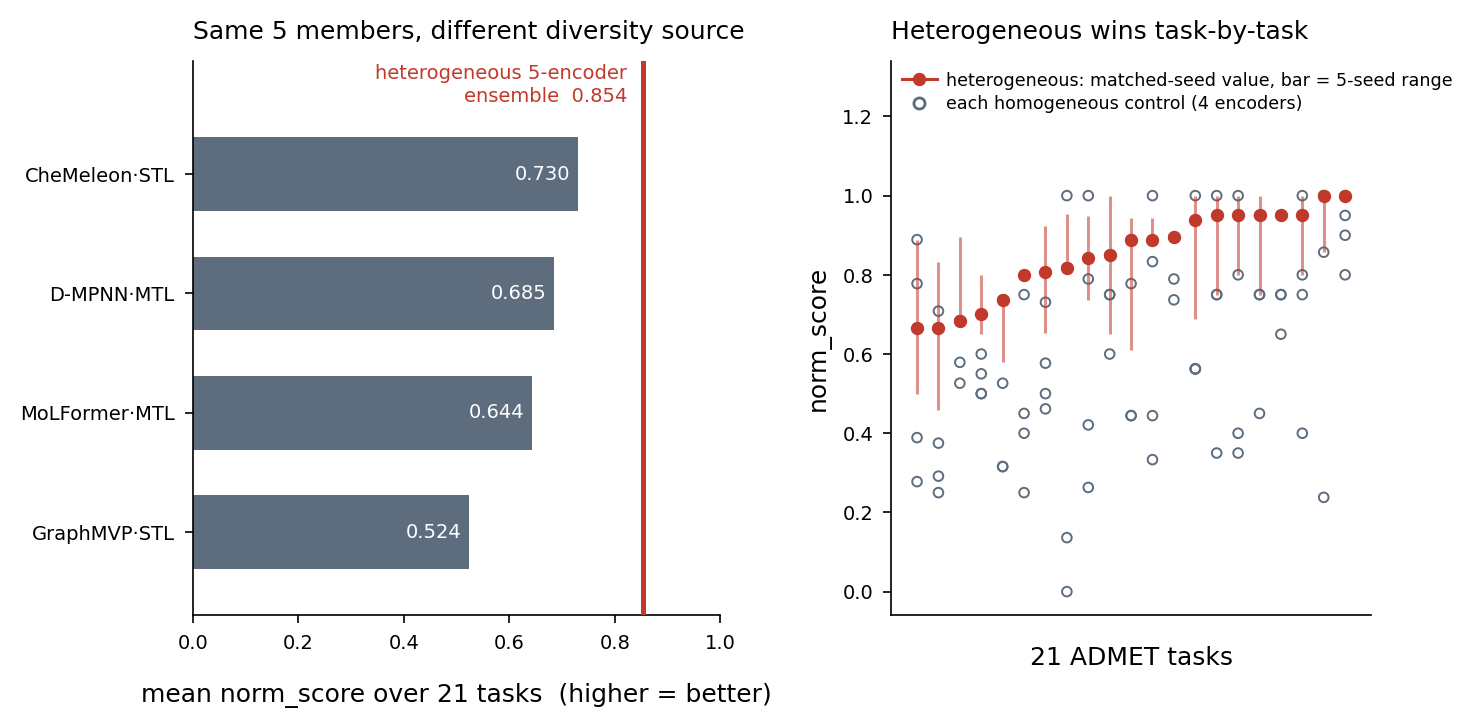

In [8]:
# === figureS8.png + Table S9 (Supplementary: homogeneous-ensemble control) ===
# Isolates encoder heterogeneity from the mere act of averaging five models. Both arms
# average exactly FIVE prediction vectors and are scored once, so member count and the
# scoring procedure are held fixed and only the SOURCE of diversity differs:
#   heterogeneous : five different encoders at a shared seed  -> pertask_norm(ENSEMBLE, True)
#                   (the matched-seed convention: per-seed raw metrics averaged, then
#                    normalized once -- identical basis to Table 4)
#   homogeneous   : one encoder, its five seeds averaged       -> pertask_norm([model], False)
#                   (seed-averaged aggregation applied to a single model = a five-member
#                    same-architecture ensemble)
# The asymmetry is conservative in the homogeneous arm's favour: it receives the variance
# reduction of seed averaging, whereas the heterogeneous arm is scored at each seed.
# MAP·STL is EXCLUDED from the control (and from the Holm family) because it is itself a
# feature-level joint fusion over three encoders, hence not a single-encoder system; its
# own five-seed ensemble is reported in the printout only, as a reference.
# Holm correction is applied WITHIN this new family of four comparisons ("family B"), so the
# eight prespecified comparisons of Table S8 (family A) keep their published p-values.

HOMOG = [("CheMeleon·STL", "stl_chemeleon"), ("D-MPNN·MTL", "mtl_dmpnn"),
         ("MoLFormer·MTL", "mtl_molformer"), ("GraphMVP·STL", "stl_graphmvp")]
HOMOG_MEMO = ("MAP·STL", "stl_map")   # reported for reference, excluded from the test

# --- heterogeneous arm: the published matched-seed per-task norm_score ---
_h9 = pertask_norm(list(ENSEMBLE), True)
_het9 = np.array([_h9[t] for t in TASKS])

# --- per-seed normalized scores, for DISPLAY of seed variability only ---
# norm_pct is monotone in the direction-aligned score, so norm_pct(mean(raw)) always lies
# within [min, max] of the per-seed norms; asserted below so the figure cannot contradict
# the point estimate it plots.
_b9 = merge_uniform(list(ENSEMBLE), True)
_seed9 = {}
for _t in TASKS:
    _m = REG[_t]["metric"]
    _g = _b9[(_b9.task == _t) & (_b9.split == "test")].dropna(subset=["y_true"])
    _seed9[_t] = [norm_pct(metric(_m, gg.y_true, gg.yhat), _t) for _, gg in _g.groupby("seed")]
_lo9 = np.array([min(_seed9[t]) for t in TASKS])
_hi9 = np.array([max(_seed9[t]) for t in TASKS])
assert ((_lo9 - 1e-12 <= _het9) & (_het9 <= _hi9 + 1e-12)).all(), \
    "matched-seed value falls outside its own per-seed norm range"

# --- homogeneous arms + paired one-sided Wilcoxon ---
_rows9, _p9, _pt9 = [], [], {}
for _lab, _mod in HOMOG:
    _d = pertask_norm([_mod], False)
    _v = np.array([_d[t] for t in TASKS]); _pt9[_lab] = _v
    _diff = _het9 - _v
    _w = int((_diff > 1e-9).sum()); _ti = int((abs(_diff) <= 1e-9).sum()); _l = int((_diff < -1e-9).sum())
    _W, _pv = wilcoxon(_het9, _v, alternative="greater")
    _p9.append(_pv)
    _rows9.append(dict(control=_lab, homog_norm=round(float(_v.mean()), 3),
                       ensemble_matched=round(float(_het9.mean()), 3),
                       mean_delta=round(float(_diff.mean()), 3),
                       median_delta=round(float(np.median(_diff)), 3),
                       wtl=f"{_w}/{_ti}/{_l}", W=float(_W), p_raw=float(_pv)))
_adj9 = multipletests(_p9, method="holm")[1]          # Holm within family B only
for _r, _a in zip(_rows9, _adj9):
    _r["p_holm_familyB"] = float(_a)
tableS9_homogeneous_control = register("tableS9_homogeneous_control", pd.DataFrame(_rows9))

_memo_d = pertask_norm([HOMOG_MEMO[1]], False)
_memo_v = float(np.mean([_memo_d[t] for t in TASKS]))

# --- figure ---
apply_figure_style(sizes=(9, 8, 7))
_HET_C, _HOM_C = "#c0392b", "#5d6d7e"
_ord9 = sorted(range(len(HOMOG)), key=lambda i: _pt9[HOMOG[i][0]].mean())
_labs9 = [HOMOG[i][0] for i in _ord9]
_vals9 = [float(_pt9[l].mean()) for l in _labs9]

figS8, (_axA, _axB) = plt.subplots(1, 2, figsize=(7.6, 3.6),
                                   gridspec_kw=dict(width_ratios=[1.1, 1.0], wspace=0.34))
_y9 = np.arange(len(_labs9))
_axA.barh(_y9, _vals9, color=_HOM_C, height=0.62, zorder=2)
_axA.axvline(_het9.mean(), color=_HET_C, lw=1.8, zorder=5)
_axA.annotate(f"heterogeneous 5-encoder\nensemble  {_het9.mean():.3f}",
              xy=(_het9.mean(), len(_labs9) - 0.4), xytext=(_het9.mean() - 0.03, len(_labs9) - 0.25),
              color=_HET_C, fontsize=7, ha="right", va="center", linespacing=1.3)
_axA.set_yticks(_y9); _axA.set_yticklabels(_labs9)
for _yy, _v in zip(_y9, _vals9):
    _axA.text(_v - 0.015, _yy, f"{_v:.3f}", ha="right", va="center", color="white", fontsize=7)
_axA.set_xlim(0, 1.0); _axA.set_ylim(-0.7, len(_labs9) - 0.05)
_axA.set_xlabel("mean norm_score over 21 tasks  (higher = better)", labelpad=11)
_axA.set_title("Same 5 members, different diversity source", loc="left", pad=8)

_o9 = np.argsort(_het9); _x9 = np.arange(len(TASKS))
_axB.vlines(_x9, _lo9[_o9], _hi9[_o9], color=_HET_C, lw=1.1, alpha=0.55, zorder=3)
_axB.plot(_x9, _het9[_o9], "o", ms=3.8, color=_HET_C, zorder=5)
for _lab, _ in HOMOG:
    _axB.scatter(_x9, _pt9[_lab][_o9], s=12, marker="o", facecolors="none",
                 edgecolors=_HOM_C, lw=0.7, zorder=2)
_axB.set_xticks([]); _axB.set_xlabel("21 ADMET tasks", labelpad=11)
_axB.set_ylabel("norm_score")
_axB.set_title("Heterogeneous wins task-by-task", loc="left", pad=8)
_axB.set_ylim(-0.06, 1.34); _axB.set_xlim(-1.2, len(TASKS) + 0.2)
_axB.legend(handles=[
    mpl.lines.Line2D([], [], color=_HET_C, marker="o", ms=3.8, lw=1.1,
                     label="heterogeneous: matched-seed value, bar = 5-seed range"),
    mpl.lines.Line2D([], [], color=_HOM_C, marker="o", ms=4, lw=0, mfc="none",
                     label="each homogeneous control (4 encoders)")],
    loc="upper left", frameon=False, fontsize=6.3, handletextpad=0.5,
    borderpad=0.1, labelspacing=0.32)
figS8.savefig(os.path.join(OUTDIR, "figureS8.png"), dpi=300, bbox_inches="tight")

# --- consistency checks against the manuscript ---
assert len(TASKS) == 21
_pub9 = float(np.mean([e["within_norm"] for e in _PT["t4"] if e["task"] != "Bioavailability_Ma"]))
assert abs(_het9.mean() - _pub9) < 2e-3, \
    f"heterogeneous arm {_het9.mean():.4f} must match the published matched-seed norm_score {_pub9:.4f}"
assert all(r["mean_delta"] > 0 for r in _rows9), "every control must trail the ensemble"
print("figureS8.png + tableS9_homogeneous_control written |",
      f"heterogeneous (matched-seed) {_het9.mean():.4f} |",
      "controls:", ", ".join(f"{r['control']} {r['homog_norm']:.3f} (Holm p={r['p_holm_familyB']:.4f})"
                             for r in _rows9),
      f"| excluded MAP·STL five-seed reference {_memo_v:.3f}",
      f"| mean 5-seed interval width {float((_hi9-_lo9).mean()):.3f}")


*Figure S8. Homogeneous-ensemble control: encoder heterogeneity versus seed diversity at a fixed member count.* Each arm averages exactly five prediction vectors and is scored once, so the number of members and the scoring procedure are held fixed and only the source of diversity differs. **(a)** Mean norm_score over the 21 evaluation tasks for the four homogeneous ensembles — one backbone's five seed replicates averaged — against the heterogeneous five-encoder ensemble (Tetra-Fuse, matched-seed track, red line). Even the strongest single encoder, seed-ensembled five-fold, remains well below the heterogeneous ensemble. **(b)** Per-task view, tasks sorted by ensemble score. The red point is the published matched-seed norm_score and the bar spans the minimum and maximum of the five seed-wise normalized scores; the bar displays seed variability and is not the quantity entering the test. Open circles are the four homogeneous controls. One-sided paired Wilcoxon signed-rank tests with Holm correction applied within this family of four comparisons, separately from the eight prespecified comparisons of Table S8, are reported in Table S9. MAP·STL is excluded from the control because it is itself a feature-level joint fusion over three encoders and therefore not a single-encoder, homogeneous system.

## Table S9 — Homogeneous-ensemble control (4 comparisons, Holm family B)
Mean/median Δnorm_score, win/tie/loss, one-sided paired Wilcoxon statistic, and raw and Holm-corrected p for the heterogeneous ensemble against each same-architecture five-seed ensemble. Computed by the Fig. S8 cell above.